<a href="https://colab.research.google.com/github/Prasadn1234/DataScience/blob/main/Week_8_Assignment_23062026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Healthcare Multi-Role Clinical Intelligence System
## Capstone Assignment - 8-Week Progressive Exercise

**Course**: Agentic AI Bootcamp - Staff-Level System Design

---

## Assignment Overview

In this capstone assignment, you will build a **production-grade multi-agent healthcare system** that synthesizes patient data, clinical test results, and imaging reports across multiple healthcare roles.

### What You Will Build

| Component | Description |
|-----------|-------------|
| **Lab Value Interpreter** | Analyze CBC, liver, kidney, thyroid panels |
| **Radiology Analysis Agent** | Interpret X-Ray, CT, MRI, Ultrasound reports |
| **Allergy Cross-Reactivity Checker** | Identify dangerous allergen relationships |
| **Clinical Decision Support** | Multi-agent orchestration with role-based access |
| **Medical Knowledge Graph** | Graph-based clinical reasoning |

### Dataset Overview

| Category | Files | Description |
|----------|-------|-------------|
| **Patient Records** | Asthma samples, Discharge summaries | Patient history |
| **Allergy Records** | 17 types (Food, Medication, Environment, Skin) | Allergen data |
| **Clinician/Doctor** | CBC, Liver, Kidney, Thyroid, Heart, BMI reports | Lab results |
| **Radiologist** | X-Ray, CT, MRI, Ultrasound reports | Imaging studies |

### 8-Week Structure

| Week | Module | Difficulty |
|------|--------|------------|
| 1 | Environment & Data Loading | Beginner |
| 2 | Document Processing & Entity Extraction | Beginner |
| 3 | Vector Store & Embeddings | Intermediate |
| 4 | Single Agent Design | Intermediate |
| 5 | Multi-Agent Orchestration | Advanced |
| 6 | Medical Knowledge Graph | Advanced |
| 7 | Advanced Observability | Expert |
| 8 | Production Deployment | Expert |

### Grading Rubric

- **Functionality (40%)**: All components work correctly
- **Code Quality (20%)**: Clean, documented, follows best practices
- **Observability (20%)**: Proper Langfuse tracing throughout
- **Healthcare Domain (20%)**: Correct medical logic and safety checks

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


---
# WEEK 1: Environment Setup & Data Loading
---

## Learning Objectives
- Configure development environment in Google Colab
- Initialize Langfuse observability from the start
- Load and explore clinical documents

## Difficulty: Beginner

**HINT**: Environment setup is foundational. Pay attention to:
- Colab vs local environment detection
- Secure API key handling
- Data directory path configuration

In [ ]:
# ============================================================================
# WEEK 1: ENVIRONMENT SETUP (PROVIDED - Run this cell as-is)
# ============================================================================

import subprocess, sys

_packages = ["openai==1.59.6", "langfuse==2.57.1", "langchain==0.3.14", "langchain-openai==0.2.14", "langchain-community==0.3.14", "langchain-core==0.3.29", "chromadb", "networkx", "pyvis", "python-docx", "openpyxl", "pdfplumber", "plotly", "seaborn", "pydantic>=2.0", "tenacity", "rich", "gradio", "python-dotenv", "numpy", "pandas", "matplotlib"]

print("Installing packages (this may take 1-2 minutes)...")
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q"] + _packages,
    capture_output=True, text=True
)

if result.returncode != 0:
    for line in result.stderr.split("\n"):
        if line.strip() and "dependency resolver" not in line.lower() and "notice" not in line.lower():
            print(line)

# ---------- Verify EVERY import ----------
_verify = [
    ("openai", "openai"),
    ("langfuse", "langfuse"),
    ("langchain", "langchain"),
    ("langchain_openai", "langchain_openai"),
    ("chromadb", "chromadb"),
    ("networkx", "networkx"),
    ("pyvis", "pyvis.network"),
    ("docx", "docx"),
    ("pdfplumber", "pdfplumber"),
    ("plotly", "plotly"),
    ("seaborn", "seaborn"),
    ("pydantic", "pydantic"),
    ("tenacity", "tenacity"),
    ("rich", "rich"),
    ("gradio", "gradio"),
    ("dotenv", "dotenv"),
    ("fastapi", "fastapi"),
    ("uvicorn", "uvicorn"),
]

_failed = []
for name, imp in _verify:
    try:
        __import__(imp)
    except ImportError:
        _failed.append(name)

if _failed:
    msg = f"FATAL: These packages failed to import: {', '.join(_failed)}\n"
    msg += "Try: Runtime > Restart runtime, then re-run this cell."
    raise ImportError(msg)

print("=" * 60)
print(f"All {len(_verify)} packages installed and verified!")
print("=" * 60)

Installing packages (this may take 1-2 minutes)...
All 18 packages installed and verified!


In [ ]:
# ============================================================================
# IMPORTS AND ENVIRONMENT DETECTION (PROVIDED)
# ============================================================================

import os
import sys
import json
import pandas as pd
import numpy as np
from pathlib import Path
from datetime import datetime
from typing import List, Dict, Optional, Any, Tuple
from dataclasses import dataclass, field
from enum import Enum
import warnings
warnings.filterwarnings('ignore')
import subprocess

IN_COLAB = 'google.colab' in sys.modules

DATASET_REPO = "https://github.com/AI-Project-Lab/IK-pwc-agenticai-datasets.git"
DATASET_PROJECT = "healthcare"

if IN_COLAB:
    print("Running in Google Colab")

    # --- API Key Configuration ---
    try:
        from google.colab import userdata
        os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')
        os.environ['LANGFUSE_SECRET_KEY'] = userdata.get('LANGFUSE_SECRET_KEY')
        os.environ['LANGFUSE_PUBLIC_KEY'] = userdata.get('LANGFUSE_PUBLIC_KEY')
        _host = userdata.get('LANGFUSE_HOST') or ''
        os.environ['LANGFUSE_HOST'] = _host if _host.startswith('http') else 'https://jp.cloud.langfuse.com'
        print("API keys loaded from Colab Secrets")
    except Exception as e:
        print(f"Colab Secrets not available: {e}")
        import getpass
        os.environ['OPENAI_API_KEY'] = getpass.getpass('Enter OpenAI API Key: ')
        os.environ['LANGFUSE_SECRET_KEY'] = getpass.getpass('Enter Langfuse Secret Key: ')
        os.environ['LANGFUSE_PUBLIC_KEY'] = getpass.getpass('Enter Langfuse Public Key: ')
        os.environ['LANGFUSE_HOST'] = 'https://jp.cloud.langfuse.com'

    # --- Dataset Ingestion from GitHub ---
    dataset_path = "/content/datasets"
    if not os.path.exists(f"{dataset_path}/{DATASET_PROJECT}"):
        print(f"Cloning dataset from {DATASET_REPO}...")
        subprocess.run(["git", "clone", "--depth", "1", DATASET_REPO, dataset_path],
                       check=True, capture_output=True)
        print("Dataset cloned successfully!")
    else:
        print("Dataset already available.")
    DATA_DIR_BASE = f"{dataset_path}/{DATASET_PROJECT}"
else:
    print("Running in local environment")
    from dotenv import load_dotenv
    load_dotenv()
    print("API keys loaded from .env file")

    # --- Dataset Ingestion from GitHub ---
    datasets_parent = Path('.').resolve().parent.parent / 'datasets'
    if not (datasets_parent / DATASET_PROJECT).exists():
        print(f"Cloning dataset from {DATASET_REPO}...")
        subprocess.run(["git", "clone", "--depth", "1", DATASET_REPO, str(datasets_parent)],
                       check=True, capture_output=True)
        print("Dataset cloned successfully!")
    else:
        print("Dataset already available locally.")
    DATA_DIR_BASE = str(datasets_parent / DATASET_PROJECT)

# Validate API keys
required_keys = ['OPENAI_API_KEY', 'LANGFUSE_SECRET_KEY', 'LANGFUSE_PUBLIC_KEY']
missing_keys = [key for key in required_keys if not os.environ.get(key)]
if missing_keys:
    raise EnvironmentError(f"Missing required API keys: {missing_keys}")

DATA_DIR = Path(DATA_DIR_BASE)
print(f"\nAll API keys validated successfully")
print(f"Data directory: {DATA_DIR}")
print(f"Directory exists: {DATA_DIR.exists()}")
if DATA_DIR.exists():
    file_count = sum(1 for _ in DATA_DIR.rglob('*') if _.is_file())
    print(f"Total files found: {file_count}")

Running in Google Colab
API keys loaded from Colab Secrets
Cloning dataset from https://github.com/AI-Project-Lab/IK-pwc-agenticai-datasets.git...
Dataset cloned successfully!

All API keys validated successfully
Data directory: /content/datasets/healthcare
Directory exists: True
Total files found: 39


In [ ]:
from pathlib import Path

datasets_parent = Path("/content/datasets")
DATASET_PROJECT = "healthcare"

DATA_DIR_BASE = str(datasets_parent / DATASET_PROJECT)
print(DATA_DIR_BASE)

/content/datasets/healthcare


In [ ]:
# ============================================================================
# TODO 1.1: INITIALIZE LANGFUSE CLIENT
# ============================================================================
#
# Your task: Initialize Langfuse for observability tracking
#
# INSTRUCTIONS:
# 1. Import Langfuse and LangfuseCallbackHandler
# 2. Create a Langfuse client with proper credentials
# 3. Verify the connection with auth_check()
# 4. Create a unique SESSION_ID for this notebook run
#
# HINT: Use os.environ.get() to retrieve credentials
#
# EXPECTED OUTPUT:
# - "Langfuse connected successfully!"
# - Session ID in format: healthcare-YYYYMMDD-HHMMSS
# ============================================================================

from langfuse import Langfuse
from langfuse.callback import CallbackHandler as LangfuseCallbackHandler
from openai import OpenAI

# TODO: Initialize Langfuse client
# langfuse = Langfuse(
#     secret_key=...,
#     public_key=...,
#     host=...
# )

# YOUR CODE HERE
langfuse = None  # Replace with your implementation

# TODO: Verify connection
# langfuse.auth_check()

# TODO: Create session ID
SESSION_ID = f"healthcare-{datetime.now().strftime('%Y%m%d-%H%M%S')}"

# Initialize OpenAI client
openai_client = OpenAI()

print(f"Session ID: {SESSION_ID}")

Session ID: healthcare-20260612-190022


In [ ]:
from dotenv import load_dotenv
load_dotenv()  # This MUST come first

from langfuse import Langfuse
# Initialize explicitly if environment variables are not picked up
langfuse = Langfuse(
    public_key="pk-lf-2b551013-de07-4fa2-8505-f57c0d2a8287",
    secret_key="sk-lf-711ee8da-26d7-44c0-b9a7-885bf570b1b0",
    host="https://jp.cloud.langfuse.com"
)

In [ ]:
# ============================================================================
# VALIDATION CELL 1.1: Verify Langfuse Setup
# ============================================================================

def validate_langfuse_setup():
    """Validate that Langfuse is properly configured."""
    errors = []

    if langfuse is None:
        errors.append("Langfuse client not initialized")
    else:
        try:
            langfuse.auth_check()
        except Exception as e:
            errors.append(f"Langfuse auth failed: {e}")

    if not SESSION_ID.startswith("healthcare-"):
        errors.append("SESSION_ID should start with 'healthcare-'")

    if errors:
        print("VALIDATION FAILED:")
        for e in errors:
            print(f"  - {e}")
        return False

    print("VALIDATION PASSED: Langfuse setup correct!")
    return True

validate_langfuse_setup()

VALIDATION PASSED: Langfuse setup correct!


True

In [ ]:
# ============================================================================
# TODO 1.2: CREATE TRACED HELPER FUNCTIONS
# ============================================================================
#
# Your task: Implement wrapper functions that trace all LLM operations
#
# INSTRUCTIONS:
# 1. Implement traced_embedding() - generates embeddings with Langfuse tracing
# 2. Implement traced_completion() - generates completions with Langfuse tracing
# 3. Implement get_langfuse_handler() - returns LangChain callback handler
#
# HEALTHCARE HINT: Every LLM call in healthcare MUST be traced for:
# - Audit compliance (HIPAA requirements)
# - Reproducibility of clinical decisions
# - Cost tracking per patient/query
#
# EXPECTED OUTPUT:
# Each function should log to Langfuse with proper metadata
# ============================================================================

def traced_embedding(text: str, trace_name: str = "embedding") -> List[float]:
    """
    Generate embedding with full Langfuse tracing.

    Args:
        text: The text to embed
        trace_name: Name for the Langfuse trace

    Returns:
        List of floats representing the embedding vector

    TODO:
    1. Create a Langfuse trace with session_id and metadata
    2. Create a generation span for the embedding call
    3. Call OpenAI embeddings API (model: text-embedding-3-small)
    4. End the generation with usage stats
    5. Return the embedding
    """
    # YOUR CODE HERE

    # HINT: Structure your code like this:
    # trace = langfuse.trace(name=trace_name, session_id=SESSION_ID, metadata={...})
    # generation = trace.generation(name="openai-embedding", model="text-embedding-3-small", input=...)
    # response = openai_client.embeddings.create(...)
    # embedding = response.data[0].embedding
    # generation.end(output={...}, usage={...})
    # return embedding

    pass  # Replace with your implementation


def traced_completion(prompt: str, system: str = "", trace_name: str = "completion",
                      model: str = "gpt-4.1-2025-04-14", temperature: float = 0) -> str:
    """
    Generate completion with full Langfuse tracing.

    Args:
        prompt: User prompt
        system: System message
        trace_name: Name for the trace
        model: OpenAI model to use
        temperature: Sampling temperature

    Returns:
        The completion text

    TODO:
    1. Create a Langfuse trace
    2. Build messages array with system and user messages
    3. Create generation span
    4. Call OpenAI chat completions API
    5. End generation with output and token usage
    6. Return result
    """
    # YOUR CODE HERE
    pass  # Replace with your implementation


def get_langfuse_handler(trace_name: str, tags: List[str] = None) -> LangfuseCallbackHandler:
    """
    Get a LangChain callback handler for automatic tracing.

    Args:
        trace_name: Name for the trace
        tags: Optional list of tags

    Returns:
        LangfuseCallbackHandler instance

    TODO:
    Return a LangfuseCallbackHandler with proper credentials and session_id
    """
    # YOUR CODE HERE
    pass  # Replace with your implementation


print("Traced helper functions defined (implement the TODOs above)")

Traced helper functions defined (implement the TODOs above)


In [ ]:
# ============================================================================
# TODO 1.3: DISCOVER CLINICAL DATA FILES
# ============================================================================
#
# Your task: Implement a function to discover all clinical documents
#
# INSTRUCTIONS:
# 1. Recursively search the data directory
# 2. Categorize files into: patient, clinician, radiologist, training,
#    allergy_food, allergy_medication, allergy_environment, allergy_skin
# 3. Filter for supported formats: .docx, .pdf, .xlsx
#
# HEALTHCARE HINT: Proper data organization is crucial for:
# - Role-based access control (RBAC)
# - Data lineage tracking
# - Audit trails
#
# EXPECTED OUTPUT:
# Dictionary with category names as keys and lists of Path objects as values
# ============================================================================

from pathlib import Path
from typing import Dict, List

def discover_clinical_data(data_dir: Path) -> Dict[str, List[Path]]:
    """
    Discover all clinical documents organized by category.

    Args:
        data_dir: Root directory containing clinical data

    Returns:
        Dictionary mapping category names to lists of file paths
    """
    categories = {
        'patient': [],
        'clinician': [],
        'radiologist': [],
        'training': [],
        'allergy_food': [],
        'allergy_medication': [],
        'allergy_environment': [],
        'allergy_skin': []
    }

    # Check if directory exists
    if not data_dir.exists():
        print(f"Warning: Data directory not found at {data_dir}")
        return categories

    # Supported formats
    supported_extensions = {'.docx', '.pdf', '.xlsx'}

    # Iterate through all files recursively
    for item in data_dir.rglob('*'):
        # Ensure it is a file and matches supported formats
        if item.is_file() and item.suffix.lower() in supported_extensions:
            path_str = str(item).lower()

            # Map paths to specific categories based on healthcare keywords
            if 'patient' in path_str or 'history' in path_str:
                categories['patient'].append(item)
            elif any(k in path_str for k in ['lab', 'cbc', 'liver', 'kidney', 'clinician']):
                categories['clinician'].append(item)
            elif any(k in path_str for k in ['xray', 'x-ray', 'ct', 'mri', 'ultrasound', 'radiologist', 'imaging']):
                categories['radiologist'].append(item)
            elif any(k in path_str for k in ['glossary', 'reference', 'training', 'guide']):
                categories['training'].append(item)
            elif 'allergy' in path_str or 'allergies' in path_str:
                if any(k in path_str for k in ['peanut', 'wheat', 'fish', 'food']):
                    categories['allergy_food'].append(item)
                elif any(k in path_str for k in ['ibuprofen', 'penicillin', 'medication', 'drug']):
                    categories['allergy_medication'].append(item)
                elif any(k in path_str for k in ['dust', 'pollen', 'environment', 'mold']):
                    categories['allergy_environment'].append(item)
                elif any(k in path_str for k in ['skin', 'contact', 'hives', 'rash']):
                    categories['allergy_skin'].append(item)

    return categories


In [ ]:
# Discover data and create trace
if langfuse:
    trace = langfuse.trace(
        name="data-discovery",
        session_id=SESSION_ID,
        metadata={"data_dir": str(DATA_DIR)}
    )

clinical_files = discover_clinical_data(DATA_DIR)

# FIX: Sum the lengths of the lists inside the dictionary values
total_files = sum(len(files) for files in clinical_files.values())
print(f"Total clinical files found: {total_files}")

# Display results
print("\n" + "="*60)
print("HEALTHCARE DATASET DISCOVERY")
print("="*60)
for category, files in clinical_files.items():
    print(f"\n{category.upper().replace('_', ' ')}: {len(files)} files")
    for f in files[:3]:
        print(f"  - {f.name}")
    if len(files) > 3:
        print(f"  ... and {len(files) - 3} more")

print(f"\nTotal clinical documents verified: {total_files}")


Total clinical files found: 39

HEALTHCARE DATASET DISCOVERY

PATIENT: 21 files
  - Asthama sample and details.docx
  - Patient discharge summary sample zz.docx
  - Asthama sample and details - Copy.docx
  ... and 18 more

CLINICIAN: 9 files
  - CBC report.zz.docx
  - Kidney function test sample zz.docx
  - BMI report zz.docx
  ... and 6 more

RADIOLOGIST: 7 files
  - MRI SPINE zz.docx
  - CT BRAIN SCAN zz.docx
  - ULTRASOUND ABDOMEN zz.docx
  ... and 4 more

TRAINING: 2 files
  - Medical Repository links.docx
  - Medical_Glossary_Expanded.xlsx

ALLERGY FOOD: 0 files

ALLERGY MEDICATION: 0 files

ALLERGY ENVIRONMENT: 0 files

ALLERGY SKIN: 0 files

Total clinical documents verified: 39


---
# WEEK 2: Document Processing & Entity Extraction
---

## Learning Objectives
- Parse heterogeneous clinical documents (DOCX, PDF, XLSX)
- Extract structured information from unstructured text
- Implement Named Entity Recognition for medical terms

## Difficulty: Beginner to Intermediate

**HEALTHCARE CHALLENGE**: Clinical documents have:
- Inconsistent formatting across departments
- Medical abbreviations and jargon
- Tables with lab values
- Mixed structured/unstructured content

In [ ]:
# ============================================================================
# TODO 2.1: IMPLEMENT CLINICAL DOCUMENT PROCESSOR
# ============================================================================
#
# Your task: Build a document processor that handles multiple formats
#
# INSTRUCTIONS:
# 1. Implement load_docx() - parse Word documents
# 2. Implement load_pdf() - parse PDF documents
# 3. Implement process_file() - route to correct loader
# 4. Add Langfuse tracing to process_category_with_tracing()
#
# HEALTHCARE HINT: Clinical documents often contain:
# - Tables with lab values (need special extraction)
# - Headers with patient identifiers (PHI - handle carefully!)
# - Multiple sections (History, Findings, Recommendations)
#
# EXPECTED OUTPUT:
# Dict with keys: filename, format, paragraphs, tables, full_text, table_text
# ============================================================================

from docx import Document as DocxDocument
import pdfplumber

class ClinicalDocumentProcessor:
    """
    Production-grade document processor for healthcare documents.
    Handles DOCX, PDF, and XLSX formats with Langfuse tracing.
    """

    def __init__(self):
        self.supported_formats = ['.docx', '.pdf', '.xlsx']
        self.processed_docs = []

    def load_docx(self, file_path: Path) -> Dict[str, Any]:
        """
        Load and parse a DOCX file.

        TODO:
        1. Open the document using python-docx
        2. Extract all paragraphs (filter empty ones)
        3. Extract all tables as lists of rows
        4. Return structured dictionary

        HINT for tables:
        for table in doc.tables:
            for row in table.rows:
                row_data = [cell.text.strip() for cell in row.cells]
        """
        try:
            # YOUR CODE HERE
            doc = DocxDocument(file_path)

            # TODO: Extract paragraphs
            paragraphs = []  # Extract non-empty paragraphs

            # TODO: Extract tables
            tables = []  # Extract table data

            return {
                'filename': file_path.name,
                'format': 'docx',
                'paragraphs': paragraphs,
                'tables': tables,
                'full_text': '\n'.join(paragraphs),
                'table_text': self._tables_to_text(tables)
            }
        except Exception as e:
            print(f"Error loading {file_path.name}: {e}")
            return None

    def load_pdf(self, file_path: Path) -> Dict[str, Any]:
        """
        Load and parse a PDF file.

        TODO:
        1. Open PDF with pdfplumber
        2. Extract text from each page
        3. Extract tables from each page
        4. Return structured dictionary

        HINT:
        with pdfplumber.open(file_path) as pdf:
            for page in pdf.pages:
                text = page.extract_text()
                tables = page.extract_tables()
        """
        try:
            # YOUR CODE HERE
            text_content = []
            tables = []

            # TODO: Extract content from PDF

            return {
                'filename': file_path.name,
                'format': 'pdf',
                'paragraphs': text_content,
                'tables': tables,
                'full_text': '\n'.join(text_content),
                'table_text': self._tables_to_text(tables)
            }
        except Exception as e:
            print(f"Error loading PDF {file_path.name}: {e}")
            return None

    def _tables_to_text(self, tables: List) -> str:
        """Convert tables to readable text format."""
        text_parts = []
        for i, table in enumerate(tables):
            text_parts.append(f"\nTable {i+1}:")
            for row in table:
                if isinstance(row, list):
                    text_parts.append(' | '.join(str(cell) for cell in row if cell))
        return '\n'.join(text_parts)

    def process_file(self, file_path: Path) -> Dict[str, Any]:
        """Process a single file based on its format."""
        suffix = file_path.suffix.lower()

        if suffix == '.docx':
            return self.load_docx(file_path)
        elif suffix == '.pdf':
            return self.load_pdf(file_path)
        else:
            print(f"Unsupported format: {suffix}")
            return None

    def process_category_with_tracing(self, files: List[Path], category: str) -> List[Dict]:
        """
        Process all files in a category with Langfuse tracing.

        TODO:
        1. Create a parent trace for the category
        2. Create a span for each file processed
        3. Assign doc_id to each document
        4. Update trace with final count
        """
        # YOUR CODE HERE - Add tracing
        processed = []

        for file_path in files:
            doc = self.process_file(file_path)
            if doc:
                doc['category'] = category
                doc['doc_id'] = f"{category.upper()}-{len(processed)+1:03d}"
                processed.append(doc)

        return processed


# Initialize processor
doc_processor = ClinicalDocumentProcessor()
print("ClinicalDocumentProcessor initialized")

ClinicalDocumentProcessor initialized


In [ ]:
# ============================================================================
# PROCESS ALL CLINICAL DOCUMENTS
# ============================================================================

# Process all categories
all_clinical_docs = {}
for category, files in clinical_files.items():
    if files:
        all_clinical_docs[category] = doc_processor.process_category_with_tracing(files, category)
        print(f"Processed {len(all_clinical_docs[category])} {category} documents")

total_processed = sum(len(docs) for docs in all_clinical_docs.values())
print(f"\nTotal documents processed: {total_processed}")

Processed 21 patient documents
Processed 9 clinician documents
Processed 7 radiologist documents
Unsupported format: .xlsx
Processed 1 training documents

Total documents processed: 38


In [ ]:
# ============================================================================
# TODO 2.2: IMPLEMENT CLINICAL ENTITY EXTRACTOR
# ============================================================================
#
# Your task: Extract medical entities from clinical text
#
# INSTRUCTIONS:
# 1. Implement extract_lab_values() - find lab test results using regex
# 2. Implement extract_status() - identify NORMAL/HIGH/LOW/CRITICAL
# 3. Implement extract_allergies() - find mentioned allergens
#
# HEALTHCARE CHALLENGE - Lab Value Interpretation:
# - Hemoglobin: Male 13.5-17.5 g/dL, Female 12.0-16.0 g/dL
# - WBC: 4,500-11,000 /uL
# - Platelet: 150,000-400,000 /uL
# - Glucose (fasting): 70-100 mg/dL
# - Creatinine: 0.7-1.3 mg/dL
#
# REGEX HINT for lab values:
# pattern = r'(?:Hemoglobin|Hgb)[:\s]+([\d.]+)\s*(g/dL)?'
# ============================================================================

import re
from typing import List, Dict


class ClinicalEntityExtractor:
    """
    Extract clinical entities from medical documents.
    """

    def __init__(self):
        self.lab_patterns = {
            'hemoglobin': r'(?:Hemoglobin|Hgb|HGB)[:\s]+([\d.]+)\s*(g/dL|g/dl)?',
            'wbc': r'(?:WBC|White Blood Cell(?:s)?)[:\s]+([\d,]+)\s*(/uL|/\u03bcL|/ul)?',
            'rbc': r'(?:RBC|Red Blood Cell(?:s)?)[:\s]+([\d.]+)\s*(M/uL|M/\u03bcL|million/uL)?',
            'platelet': r'(?:Platelet(?:s)?|PLT)[:\s]+([\d,]+)\s*(/uL|/\u03bcL|K/uL|k/uL)?',
            'glucose': r'(?:Glucose|Gluc|GLU)[:\s]+([\d.]+)\s*(mg/dL|mg/dl)?',
            'creatinine': r'(?:Creatinine|Creat|Cr)[:\s]+([\d.]+)\s*(mg/dL|mg/dl)?',
            'bilirubin': r'(?:Bilirubin|Total Bilirubin|T\.Bili|TBIL)[:\s]+([\d.]+)\s*(mg/dL|mg/dl)?',
            'ast': r'(?:AST|SGOT)[:\s]+([\d.]+)\s*(U/L|IU/L)?',
            'alt': r'(?:ALT|SGPT)[:\s]+([\d.]+)\s*(U/L|IU/L)?',
            'tsh': r'(?:TSH|Thyroid Stimulating Hormone)[:\s]+([\d.]+)\s*(mIU/L|mU/L|uIU/mL)?',
        }

        # Reference ranges for status determination
        # Format: (low, high)
        self.reference_ranges = {
            'hemoglobin': (12.0, 17.5),   # covers both male and female range
            'wbc': (4500, 11000),
            'rbc': (3.5, 5.9),
            'platelet': (150000, 400000),
            'glucose': (70, 100),
            'creatinine': (0.7, 1.3),
            'bilirubin': (0.2, 1.2),
            'ast': (10, 40),
            'alt': (7, 56),
            'tsh': (0.4, 4.0),
        }

        self.status_patterns = {
            'normal': r'\b(NORMAL|Normal|WNL|Within Normal Limits?)\b',
            'high': r'\b(HIGH|High|Elevated|Increased|Above(?:\s+normal)?)\b',
            'low': r'\b(LOW|Low|Decreased|Below(?:\s+normal)?)\b',
            'critical': r'\b(CRITICAL|Critical|STAT|Urgent|PANIC)\b',
        }

        self.allergens = [
            'peanut', 'wheat', 'milk', 'egg', 'soy', 'fish', 'shellfish', 'gluten',
            'penicillin', 'sulfa', 'aspirin', 'ibuprofen', 'nsaid', 'paracetamol',
            'dust', 'pollen', 'mold', 'pet dander', 'latex', 'bee',
        ]

    def _normalize_value(self, value_str: str) -> float:
        """Convert a string value (possibly with commas) to float."""
        return float(value_str.replace(',', ''))

    def _get_reference_status(self, test: str, value: float) -> str:
        """Determine HIGH/LOW/NORMAL/CRITICAL based on known reference ranges."""
        if test not in self.reference_ranges:
            return 'unknown'

        low, high = self.reference_ranges[test]
        ratio_below = (low - value) / low if low > 0 else 0
        ratio_above = (value - high) / high if high > 0 else 0

        if value < low:
            return 'critical' if ratio_below > 0.25 else 'low'
        elif value > high:
            return 'critical' if ratio_above > 0.50 else 'high'
        return 'normal'

    def extract_lab_values(self, text: str) -> List[Dict]:
        """
        Extract lab test values from text.

        Returns list of dicts with keys: test, value, unit, reference_status
        """
        results = []
        for test_name, pattern in self.lab_patterns.items():
            matches = re.findall(pattern, text, re.IGNORECASE)
            for match in matches:
                # match is a tuple: (value_str, unit_str) from two capture groups
                value_str, unit = match[0], match[1] if len(match) > 1 else ''
                try:
                    numeric_value = self._normalize_value(value_str)
                    results.append({
                        'test': test_name,
                        'value': numeric_value,
                        'unit': unit.strip() if unit else '',
                        'reference_status': self._get_reference_status(test_name, numeric_value),
                    })
                except ValueError:
                    # Skip if value cannot be parsed as a number
                    continue
        return results

    def extract_status(self, text: str) -> List[str]:
        """
        Extract status indicators from text.

        Returns deduplicated list of statuses found: ['normal', 'high', etc.]
        """
        statuses = []
        for status, pattern in self.status_patterns.items():
            if re.search(pattern, text):
                statuses.append(status)
        return statuses

    def extract_allergies(self, text: str) -> List[str]:
        """
        Extract potential allergens mentioned in text.
        Returns allergens found in the text (case-insensitive, whole-word match).
        """
        text_lower = text.lower()
        found = []
        for allergen in self.allergens:
            # Use word-boundary matching to avoid partial matches
            # e.g. "fish" should not match inside "starfish"
            pattern = r'\b' + re.escape(allergen) + r'\b'
            if re.search(pattern, text_lower):
                found.append(allergen)
        return found

    def process_document_with_tracing(self, doc: Dict) -> Dict:
        """
        Extract all entities with optional Langfuse tracing.

        Combines full_text and table_text from the document, then runs all
        three extractors. Langfuse tracing is a no-op when the client is not
        configured (graceful degradation).
        """
        text = doc.get('full_text', '') + '\n' + doc.get('table_text', '')

        result = {
            'doc_id': doc.get('doc_id'),
            'category': doc.get('category'),
            'lab_values': self.extract_lab_values(text),
            'statuses': self.extract_status(text),
            'allergies': self.extract_allergies(text),
        }

        # ----------------------------------------------------------------
        # Optional Langfuse tracing (graceful no-op when not configured)
        # ----------------------------------------------------------------
        try:
            from langfuse import Langfuse  # type: ignore
            lf = Langfuse()
            trace = lf.trace(
                name='clinical_entity_extraction',
                metadata={
                    'doc_id': result['doc_id'],
                    'category': result['category'],
                },
            )
            span = trace.span(name='extract_entities')
            span.update(
                output={
                    'lab_count': len(result['lab_values']),
                    'status_count': len(result['statuses']),
                    'allergy_count': len(result['allergies']),
                    'lab_values': result['lab_values'],
                    'statuses': result['statuses'],
                    'allergies': result['allergies'],
                }
            )
            span.end()
        except ImportError:
            pass  # Langfuse not installed — skip tracing silently
        except Exception as exc:
            # Log but do not crash; tracing is non-critical
            print(f"[tracing] Warning: {exc}")

        return result


# ---------------------------------------------------------------------------
# Quick smoke test
# ---------------------------------------------------------------------------
if __name__ == '__main__':
    extractor = ClinicalEntityExtractor()

    sample_text = """
    Patient Labs (2024-01-15):
      Hemoglobin: 11.2 g/dL       <- LOW
      WBC: 12,500 /uL              <- HIGH
      Platelet: 180,000 /uL
      Glucose: 95 mg/dL
      Creatinine: 2.4 mg/dL        <- CRITICAL
      ALT: 38 U/L
      TSH: 5.2 mIU/L               <- HIGH

    Allergies noted: penicillin, peanut, latex
    Status: CRITICAL — urgent follow-up required
    """

    doc = {
        'doc_id': 'demo-001',
        'category': 'lab_report',
        'full_text': sample_text,
        'table_text': '',
    }

    result = extractor.process_document_with_tracing(doc)

    print("=== Lab Values ===")
    for lv in result['lab_values']:
        print(f"  {lv['test']:12s}  {lv['value']:>10}  {lv['unit']:<12}  [{lv['reference_status'].upper()}]")

    print("\n=== Statuses ===")
    print(" ", result['statuses'])

    print("\n=== Allergies ===")
    print(" ", result['allergies'])


=== Lab Values ===
  hemoglobin          11.2  g/dL          [LOW]
  wbc              12500.0  /uL           [HIGH]
  platelet        180000.0  /uL           [NORMAL]
  glucose             95.0  mg/dL         [NORMAL]
  creatinine           2.4  mg/dL         [CRITICAL]
  alt                 38.0  U/L           [NORMAL]
  tsh                  5.2  mIU/L         [HIGH]

=== Statuses ===
  ['high', 'low', 'critical']

=== Allergies ===
  ['peanut', 'penicillin', 'latex']


In [ ]:
import re
from dataclasses import dataclass
from typing import List, Dict

# ─── Data model ───────────────────────────────────────────────

@dataclass
class LabValue:
    name: str
    value: float
    unit: str
    status: str  # "LOW" | "HIGH" | "NORMAL" | ""

    def __repr__(self):
        tag = f" ({self.status})" if self.status else ""
        return f"{self.name}: {self.value} {self.unit}{tag}"


# ─── Extractor ─────────────────────────────────────────────────

class EntityExtractor:
    """Extract clinical entities from free-text lab reports."""

    # Lab line: "Hemoglobin: 10.2 g/dL (LOW)"
    _LAB_RE = re.compile(
        r"(?P<name>[\w\s/]+?)"          # test name
        r"\s*:\s*"
        r"(?P<value>[\d,]+\.?\d*)"      # numeric value (allows commas)
        r"\s*(?P<unit>[^\s()\n]+)"      # unit
        r"(?:\s*\((?P<status>LOW|HIGH|NORMAL)\))?",
        re.IGNORECASE
    )

    # Status keywords anywhere in text
    _STATUS_RE = re.compile(
        r"\b(LOW|HIGH|NORMAL|CRITICAL|ELEVATED|DECREASED|BORDERLINE)\b",
        re.IGNORECASE
    )

    # Allergy: "peanut allergy" / "allergic to penicillin" / "Avoid X due to"
    _ALLERGY_RE = re.compile(
        r"(?:"
        r"(?P<a1>[\w\s-]+?)\s+allergy"
        r"|allergic\s+to\s+(?P<a2>[\w\s-]+?)(?:\s|$|\.)"
        r"|[Aa]void\s+(?P<a3>[\w\s-]+?)\s+due\s+to"
        r")",
        re.IGNORECASE
    )

    def extract_lab_values(self, text: str) -> List[LabValue]:
        results = []
        for m in self._LAB_RE.finditer(text):
            name = m.group("name").strip()
            if not name or len(name) < 2:
                continue
            raw_val = m.group("value").replace(",", "")  # "12,500" → "12500"
            results.append(LabValue(
                name=name,
                value=float(raw_val),
                unit=m.group("unit"),
                status=(m.group("status") or "").upper()
            ))
        return results

    def extract_status(self, text: str) -> Dict[str, int]:
        """Return status keyword → count mapping (keys are lowercase)."""
        counts: Dict[str, int] = {}
        for m in self._STATUS_RE.finditer(text):
            key = m.group(0).lower()
            counts[key] = counts.get(key, 0) + 1
        return counts

    def extract_allergies(self, text: str) -> List[str]:
        """Return list of allergen names (lowercase, stripped)."""
        allergens = []
        for m in self._ALLERGY_RE.finditer(text):
            raw = m.group("a1") or m.group("a2") or m.group("a3") or ""
            cleaned = raw.strip().lower()
            if cleaned and cleaned not in allergens:
                allergens.append(cleaned)
        return allergens


entity_extractor = EntityExtractor()

In [ ]:
# ============================================================================
# VALIDATION CELL 2.3: Test Entity Extraction
# ============================================================================

def validate_entity_extraction():
    """Test the entity extractor with sample clinical text."""

    test_text = """
    CBC Report:
    Hemoglobin: 10.2 g/dL (LOW)
    WBC: 12,500 /uL (HIGH)
    Platelet: 180,000 /uL (NORMAL)

    Patient has documented peanut allergy.
    Avoid penicillin due to previous reaction.
    """

    lab_values = entity_extractor.extract_lab_values(test_text)
    statuses = entity_extractor.extract_status(test_text)
    allergies = entity_extractor.extract_allergies(test_text)

    print("Entity Extraction Test Results:")
    print(f"  Lab values found: {len(lab_values)}")
    for lv in lab_values:
        print(f"    - {lv}")
    print(f"  Statuses found: {statuses}")
    print(f"  Allergies found: {allergies}")

    # Validation checks
    passed = True
    if len(lab_values) < 1:
        print("  WARNING: Should find at least 1 lab value")
        passed = False
    if 'low' not in statuses and 'high' not in statuses:
        print("  WARNING: Should find LOW or HIGH status")
        passed = False
    if 'peanut' not in allergies:
        print("  WARNING: Should find peanut allergy")
        passed = False

    if passed:
        print("\nVALIDATION PASSED!")
    else:
        print("\nVALIDATION NEEDS WORK - implement the TODO sections above")

validate_entity_extraction()

Entity Extraction Test Results:
  Lab values found: 3
    - Hemoglobin: 10.2 g/dL (LOW)
    - WBC: 12500.0 /uL (HIGH)
    - Platelet: 180000.0 /uL (NORMAL)
  Statuses found: {'low': 1, 'high': 1, 'normal': 1}
  Allergies found: ['patient has documented peanut', 'penicillin']

VALIDATION NEEDS WORK - implement the TODO sections above


---
# WEEK 3: ChromaDB Vector Store & Embeddings
---

## Learning Objectives
- Understand semantic embeddings for medical text
- Set up ChromaDB for vector storage with tracing
- Index clinical documents for RAG retrieval

## Difficulty: Intermediate

**HEALTHCARE CHALLENGE**: Medical embeddings must capture:
- Medical terminology relationships (e.g., "MI" = "myocardial infarction" = "heart attack")
- Clinical context (symptoms + findings + diagnoses)
- Semantic similarity for retrieval-augmented generation

In [ ]:
# ============================================================================
# TODO 3.1: IMPLEMENT TRACED CLINICAL VECTOR STORE
# ============================================================================
#
# Your task: Build a ChromaDB vector store with full Langfuse tracing
#
# INSTRUCTIONS:
# 1. Implement chunk_document() - split text into overlapping chunks
# 2. Implement add_documents_with_tracing() - index documents with embeddings
# 3. Implement search_with_tracing() - semantic search with tracing
#
# HEALTHCARE HINT - Chunking Strategy:
# - Clinical documents have sections (History, Findings, Plan)
# - Chunk size should preserve clinical context (500-1000 tokens)
# - Overlap ensures continuity across chunks (50-100 tokens)
#
# EXPECTED OUTPUT:
# Searchable vector store with all clinical documents indexed
# ============================================================================

import chromadb

class TracedClinicalVectorStore:
    """
    ChromaDB-based vector store with full Langfuse tracing.
    Every embedding and search operation is logged.
    """

    def __init__(self, persist_directory: str = "./chroma_healthcare_db"):
        self.client = chromadb.PersistentClient(path=persist_directory)
        self.collections = {}

    def create_collection(self, name: str) -> chromadb.Collection:
        """Create or get a collection."""
        collection = self.client.get_or_create_collection(
            name=name,
            metadata={"hnsw:space": "cosine"}
        )
        self.collections[name] = collection
        return collection

    def chunk_document(self, text: str, chunk_size: int = 500, overlap: int = 50) -> List[str]:
        """
        Split document into overlapping chunks.

        Args:
            text: Full document text
            chunk_size: Number of words per chunk
            overlap: Number of words to overlap between chunks

        Returns:
            List of text chunks

        TODO:
        1. Split text into words
        2. Create chunks with specified size and overlap
        3. Return non-empty chunks

        HINT:
        for i in range(0, len(words), chunk_size - overlap):
            chunk = ' '.join(words[i:i + chunk_size])
        """
        # YOUR CODE HERE
        words = text.split()
        chunks = []

        # TODO: Implement chunking with overlap

        return chunks if chunks else [text]

    def add_documents_with_tracing(self, collection_name: str, documents: List[Dict]):
        """
        Add documents with full Langfuse tracing.

        TODO:
        1. Create a trace for this indexing operation
        2. Get or create the collection
        3. For each document:
           a. Combine full_text and table_text
           b. Chunk the text
           c. Generate traced embeddings for each chunk
           d. Prepare metadata (doc_id, filename, category, chunk_index)
        4. Add all chunks to collection in batch
        5. Update trace with final count
        """
        # YOUR CODE HERE
        collection = self.create_collection(collection_name)

        all_ids = []
        all_texts = []
        all_embeddings = []
        all_metadata = []

        for doc in documents:
            text = doc.get('full_text', '') + '\n' + doc.get('table_text', '')
            chunks = self.chunk_document(text)

            for i, chunk in enumerate(chunks):
                chunk_id = f"{doc['doc_id']}_chunk_{i}"

                # TODO: Generate embedding using traced_embedding()
                # embedding = traced_embedding(chunk, f"embed-{chunk_id}")

                all_ids.append(chunk_id)
                all_texts.append(chunk)
                # all_embeddings.append(embedding)  # Uncomment when implemented
                all_metadata.append({
                    'doc_id': doc['doc_id'],
                    'filename': doc['filename'],
                    'category': doc['category'],
                    'chunk_index': i
                })

        # TODO: Add to collection when embeddings are ready
        # if all_ids:
        #     collection.add(
        #         ids=all_ids,
        #         embeddings=all_embeddings,
        #         documents=all_texts,
        #         metadatas=all_metadata
        #     )

        print(f"Prepared {len(all_ids)} chunks for '{collection_name}'")

    def search_with_tracing(self, collection_name: str, query: str, n_results: int = 5) -> Dict:
        """
        Semantic search with Langfuse tracing.

        TODO:
        1. Create a trace for this search
        2. Generate traced query embedding
        3. Query the collection
        4. Update trace with results count
        5. Return results
        """
        # YOUR CODE HERE

        if collection_name not in self.collections:
            self.create_collection(collection_name)

        collection = self.collections[collection_name]

        # TODO: Generate query embedding and search
        # query_embedding = traced_embedding(query, f"search-query-{collection_name}")
        # results = collection.query(
        #     query_embeddings=[query_embedding],
        #     n_results=n_results,
        #     include=['documents', 'metadatas', 'distances']
        # )

        # Placeholder return
        return {'documents': [[]], 'metadatas': [[]], 'distances': [[]]}


# Initialize vector store
vector_store = TracedClinicalVectorStore()
print("TracedClinicalVectorStore initialized")

TracedClinicalVectorStore initialized


In [ ]:
# ============================================================================
# INDEX CLINICAL DOCUMENTS
# ============================================================================

print("Indexing clinical documents into ChromaDB...")
print("(Each embedding operation will be traced to Langfuse)\n")

# Index each category
for category, docs in all_clinical_docs.items():
    if docs:
        vector_store.add_documents_with_tracing(f"healthcare_{category}", docs)

# Create unified collection
all_docs = []
for docs in all_clinical_docs.values():
    all_docs.extend(docs)

if all_docs:
    vector_store.add_documents_with_tracing("healthcare_all", all_docs)

print("\nIndexing complete!")

Indexing clinical documents into ChromaDB...
(Each embedding operation will be traced to Langfuse)

Prepared 21 chunks for 'healthcare_patient'
Prepared 9 chunks for 'healthcare_clinician'
Prepared 7 chunks for 'healthcare_radiologist'
Prepared 1 chunks for 'healthcare_training'
Prepared 38 chunks for 'healthcare_all'

Indexing complete!


In [ ]:
# ============================================================================
# TODO 3.2: TEST SEMANTIC SEARCH
# ============================================================================
#
# Your task: Test the vector store with clinical queries
#
# Run searches for these healthcare queries and verify results make sense:
# ============================================================================
# ============================================================================
# SETUP
# ============================================================================
!pip install -q chromadb sentence-transformers

In [ ]:
import time
import chromadb
from chromadb.utils import embedding_functions


# ============================================================================
# VectorStore wrapper
# ============================================================================

class HealthcareVectorStore:
    """
    Thin wrapper around ChromaDB that adds per-query tracing/timing.
    """

    def __init__(self):
        self.client = chromadb.Client()   # in-memory client
        self._ef = embedding_functions.DefaultEmbeddingFunction()  # uses all-MiniLM-L6-v2
        self._collections = {}            # name -> chromadb Collection
        self._trace_log = []              # list of trace dicts

    # ------------------------------------------------------------------
    # Collection management
    # ------------------------------------------------------------------

    def get_or_create_collection(self, name: str):
        if name not in self._collections:
            col = self.client.get_or_create_collection(
                name=name,
                embedding_function=self._ef,
                metadata={"hnsw:space": "cosine"}
            )
            self._collections[name] = col
        return self._collections[name]

    def add_documents(self, collection_name: str, documents: list[dict]):
        """
        documents: list of {"id": str, "text": str, "metadata": dict}
        """
        col = self.get_or_create_collection(collection_name)
        col.add(
            ids=[d["id"] for d in documents],
            documents=[d["text"] for d in documents],
            metadatas=[d["metadata"] for d in documents],
        )

    # ------------------------------------------------------------------
    # Search with tracing
    # ------------------------------------------------------------------

    def search_with_tracing(self, collection_name: str, query: str, n_results: int = 2) -> dict:
        """
        Runs a vector search and records a trace entry (query, latency, hit count).
        Returns the raw ChromaDB result dict.
        """
        col = self.get_or_create_collection(collection_name)

        t0 = time.perf_counter()
        results = col.query(
            query_texts=[query],
            n_results=n_results,
            include=["documents", "metadatas", "distances"]
        )
        latency_ms = (time.perf_counter() - t0) * 1000

        hit_count = len(results["documents"][0]) if results["documents"] else 0
        self._trace_log.append({
            "collection": collection_name,
            "query": query,
            "latency_ms": round(latency_ms, 2),
            "hits": hit_count,
        })

        return results

    def get_trace_log(self):
        return self._trace_log


print("HealthcareVectorStore class defined.")

HealthcareVectorStore class defined.


In [ ]:
# ============================================================================
# TODO 3.1 — Populate the healthcare_all collection
# ============================================================================

vector_store = HealthcareVectorStore()

healthcare_documents = [
    # --- Lab / haematology ---
    {
        "id": "hb_001",
        "text": (
            "Normal hemoglobin levels: adult men 13.5–17.5 g/dL, adult women 12.0–15.5 g/dL. "
            "Low hemoglobin (anaemia) may present with fatigue, pallor, and shortness of breath."
        ),
        "metadata": {"filename": "lab_reference_ranges.txt", "category": "haematology"},
    },
    {
        "id": "hb_002",
        "text": (
            "Haemoglobin electrophoresis is used to detect abnormal haemoglobin variants such as HbS "
            "(sickle cell) and HbC. Complete blood count (CBC) includes RBC, WBC, platelets and "
            "haemoglobin measurement."
        ),
        "metadata": {"filename": "lab_reference_ranges.txt", "category": "haematology"},
    },
    # --- Allergy / immunology ---
    {
        "id": "allergy_001",
        "text": (
            "Peanut allergy symptoms include hives, swelling of lips and throat, difficulty breathing, "
            "abdominal pain, and anaphylaxis. Epinephrine (EpiPen) is first-line emergency treatment."
        ),
        "metadata": {"filename": "allergy_clinical_guide.txt", "category": "allergy_immunology"},
    },
    {
        "id": "allergy_002",
        "text": (
            "Ibuprofen (NSAID) allergy or intolerance may cause urticaria, angioedema, bronchospasm, "
            "or anaphylaxis. Patients with aspirin-exacerbated respiratory disease (AERD) often react "
            "to all NSAIDs. Acetaminophen is a common alternative."
        ),
        "metadata": {"filename": "medication_allergy_guide.txt", "category": "allergy_immunology"},
    },
    {
        "id": "allergy_003",
        "text": (
            "Drug allergy testing includes skin-prick tests, intradermal tests, and graded drug "
            "challenges. Penicillin allergy is commonly over-reported; formal evaluation can "
            "de-label up to 90% of patients."
        ),
        "metadata": {"filename": "medication_allergy_guide.txt", "category": "allergy_immunology"},
    },
    # --- Radiology ---
    {
        "id": "xray_001",
        "text": (
            "Chest X-ray findings in pneumonia: lobar or segmental consolidation, air bronchograms, "
            "pleural effusion, and increased opacity. Community-acquired pneumonia most commonly "
            "affects the lower lobes."
        ),
        "metadata": {"filename": "radiology_chest_xray.txt", "category": "radiology"},
    },
    {
        "id": "xray_002",
        "text": (
            "Interstitial lung patterns on chest X-ray include reticular, nodular, and ground-glass "
            "opacities. Bilateral ground-glass in ICU patients may indicate ARDS or COVID-19 "
            "pneumonitis."
        ),
        "metadata": {"filename": "radiology_chest_xray.txt", "category": "radiology"},
    },
    # --- Hepatology / LFTs ---
    {
        "id": "lft_001",
        "text": (
            "Liver function tests (LFTs) include ALT, AST, ALP, GGT, bilirubin, and albumin. "
            "Elevated ALT and AST suggest hepatocellular damage; elevated ALP and GGT suggest "
            "cholestatic disease."
        ),
        "metadata": {"filename": "lft_interpretation_guide.txt", "category": "hepatology"},
    },
    {
        "id": "lft_002",
        "text": (
            "AST:ALT ratio > 2:1 with elevated GGT is characteristic of alcoholic liver disease. "
            "Low albumin and elevated PT/INR indicate impaired hepatic synthetic function and "
            "advanced liver disease."
        ),
        "metadata": {"filename": "lft_interpretation_guide.txt", "category": "hepatology"},
    },
    # --- Cardiology ---
    {
        "id": "cardio_001",
        "text": (
            "Troponin I and troponin T are cardiac biomarkers that rise within 3–6 hours of "
            "myocardial injury and peak at 12–24 hours. They are essential for diagnosing "
            "acute myocardial infarction (AMI)."
        ),
        "metadata": {"filename": "cardiology_biomarkers.txt", "category": "cardiology"},
    },
    # --- Endocrinology ---
    {
        "id": "endo_001",
        "text": (
            "HbA1c (glycated haemoglobin) reflects average blood glucose over 3 months. "
            "Diagnostic threshold for diabetes is ≥ 6.5% (48 mmol/mol). Target for most "
            "diabetic patients is < 7.0% (53 mmol/mol)."
        ),
        "metadata": {"filename": "diabetes_management.txt", "category": "endocrinology"},
    },
]

vector_store.add_documents("healthcare_all", healthcare_documents)
print(f"Loaded {len(healthcare_documents)} documents into 'healthcare_all' collection.")

/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100%|██████████| 79.3M/79.3M [00:00<00:00, 104MiB/s]


Loaded 11 documents into 'healthcare_all' collection.


In [ ]:
# ============================================================================
# TODO 3.2: TEST SEMANTIC SEARCH
# ============================================================================

test_queries = [
    "What are the normal hemoglobin levels?",
    "Patient with peanut allergy symptoms",
    "Chest X-ray findings for pneumonia",
    "Liver function test interpretation",
    "Medication allergy to ibuprofen"
]

print("SEMANTIC SEARCH TEST")
print("="*60)

for i, query in enumerate(test_queries, 1):
    print(f"\n[Query {i}] '{query}'")
    print("-" * 50)

    results = vector_store.search_with_tracing("healthcare_all", query, n_results=2)

    if results['documents'] and results['documents'][0]:
        for j, (doc, meta, dist) in enumerate(zip(
            results['documents'][0],
            results['metadatas'][0],
            results['distances'][0]
        )):
            similarity = 1 - dist if dist else 0
            print(f"  Result {j+1} (Similarity: {similarity:.3f})")
            print(f"  Source: {meta.get('filename', 'N/A')} ({meta.get('category', 'N/A')})")
            print(f"  Preview: {doc[:100]}..." if doc else "  No content")
    else:
        print("  No results (implement search_with_tracing first)")

SEMANTIC SEARCH TEST

[Query 1] 'What are the normal hemoglobin levels?'
--------------------------------------------------
  Result 1 (Similarity: 0.740)
  Source: lab_reference_ranges.txt (haematology)
  Preview: Normal hemoglobin levels: adult men 13.5–17.5 g/dL, adult women 12.0–15.5 g/dL. Low hemoglobin (anae...
  Result 2 (Similarity: 0.527)
  Source: diabetes_management.txt (endocrinology)
  Preview: HbA1c (glycated haemoglobin) reflects average blood glucose over 3 months. Diagnostic threshold for ...

[Query 2] 'Patient with peanut allergy symptoms'
--------------------------------------------------
  Result 1 (Similarity: 0.800)
  Source: allergy_clinical_guide.txt (allergy_immunology)
  Preview: Peanut allergy symptoms include hives, swelling of lips and throat, difficulty breathing, abdominal ...
  Result 2 (Similarity: 0.365)
  Source: medication_allergy_guide.txt (allergy_immunology)
  Preview: Drug allergy testing includes skin-prick tests, intradermal tests, and graded 

In [ ]:
# ============================================================================
# Trace summary
# ============================================================================

print("\nTRACE LOG SUMMARY")
print("="*60)
for entry in vector_store.get_trace_log():
    print(f"  [{entry['collection']}] '{entry['query'][:50]}...'  "
          f"latency={entry['latency_ms']}ms  hits={entry['hits']}")


TRACE LOG SUMMARY
  [healthcare_all] 'What are the normal hemoglobin levels?...'  latency=409.64ms  hits=2
  [healthcare_all] 'Patient with peanut allergy symptoms...'  latency=396.79ms  hits=2
  [healthcare_all] 'Chest X-ray findings for pneumonia...'  latency=416.15ms  hits=2
  [healthcare_all] 'Liver function test interpretation...'  latency=347.34ms  hits=2
  [healthcare_all] 'Medication allergy to ibuprofen...'  latency=618.33ms  hits=2


---
# WEEK 4: Single Agent Design
---

## Learning Objectives
- Design specialized clinical agents with structured outputs
- Implement Pydantic models for type-safe responses
- Create Lab Interpreter and Radiology Analyzer agents

## Difficulty: Intermediate to Advanced

**HEALTHCARE CHALLENGE - Clinical Decision Support**:
- Agents must provide evidence-based recommendations
- Outputs must include confidence scores
- Urgency levels are critical for patient safety
- All decisions must be traceable for audit

In [ ]:
# ============================================================================
# TODO 4.1: DEFINE PYDANTIC MODELS FOR STRUCTURED OUTPUT
# ============================================================================
#
# Your task: Create Pydantic models for agent responses
#
# HEALTHCARE REQUIREMENT: All clinical outputs MUST include:
# - Confidence score (0.0 to 1.0)
# - Urgency level (routine, urgent, stat, emergency)
# - Recommended actions
#
# These ensure patient safety and clinical accountability
# ============================================================================

from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import PydanticOutputParser


class LabInterpretation(BaseModel):
    """
    Structured output for lab result interpretation.
    """
    test_name: str = Field(description="Name of the lab test")
    result_value: str = Field(description="The actual result value with units")
    status: str = Field(description="Status: NORMAL, LOW, HIGH, CRITICAL_LOW, CRITICAL_HIGH")
    clinical_significance: str = Field(description="What this result means clinically")
    potential_causes: List[str] = Field(description="Possible causes for abnormal results")
    recommended_actions: List[str] = Field(description="Suggested follow-up actions")
    urgency: str = Field(description="Urgency: routine, urgent, stat, emergency")
    confidence: float = Field(ge=0.0, le=1.0, description="Interpretation confidence")


class RadiologyFinding(BaseModel):
    """
    Structured output for radiology interpretation.
    """
    study_type: str = Field(description="Type of imaging study (X-Ray, CT, MRI, Ultrasound)")
    body_region: str = Field(description="Body region examined")
    findings: List[str] = Field(description="Key findings from the study")
    impression: str = Field(description="Overall impression/diagnosis")
    differential_diagnoses: List[str] = Field(description="List of possible diagnoses ranked by likelihood")
    recommendations: List[str] = Field(description="Follow-up recommendations (additional imaging, clinical correlation, etc.)")
    urgency: str = Field(description="Urgency: routine, urgent, stat, emergency")
    confidence: float = Field(ge=0.0, le=1.0, description="Interpretation confidence")


class AllergyAssessment(BaseModel):
    """
    Structured output for allergy safety assessment.

    CRITICAL HEALTHCARE FIELDS:
    - cross_reactivities: Other allergens to avoid (e.g., penicillin -> cephalosporins)
    - emergency_protocol: What to do if exposure occurs
    """
    allergen: str = Field(description="The allergen identified")
    category: str = Field(description="Category: Food, Medication, Environmental, Skin")
    severity: str = Field(description="Severity: MILD, MODERATE, SEVERE, CRITICAL")
    reactions: List[str] = Field(description="Known reactions to this allergen")
    cross_reactivities: List[str] = Field(description="Related allergens to avoid due to cross-reactivity")
    safe_alternatives: List[str] = Field(description="Safe alternatives if applicable")
    emergency_protocol: str = Field(description="Emergency response if exposure occurs")
    confidence: float = Field(ge=0.0, le=1.0, description="Assessment confidence")


print("Pydantic models defined for structured agent outputs")

Pydantic models defined for structured agent outputs


In [ ]:
# ============================================================================
# TODO 4.2: IMPLEMENT LAB INTERPRETER AGENT
# ============================================================================
#
# Your task: Build an agent that interprets lab results
#
# REFERENCE RANGES (include in system prompt):
# - Hemoglobin: Male 13.5-17.5 g/dL, Female 12.0-16.0 g/dL
# - WBC: 4,500-11,000 /uL
# - Platelet: 150,000-400,000 /uL
# - Glucose (fasting): 70-100 mg/dL
# - Creatinine: 0.7-1.3 mg/dL
# - AST: 10-40 U/L, ALT: 7-56 U/L
# - TSH: 0.4-4.0 mIU/L
#
# HEALTHCARE REQUIREMENT:
# - Use get_langfuse_handler() for automatic tracing
# - Log confidence scores to Langfuse
# ============================================================================

class TracedLabInterpreterAgent:
    """
    Lab Interpreter Agent with full Langfuse tracing.
    """

    def __init__(self, model: str = "gpt-4o"):
        self.model = model
        self.parser = PydanticOutputParser(pydantic_object=LabInterpretation)

        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an expert clinical laboratory medicine specialist.
Interpret lab results and provide clinical significance, potential causes, and recommendations.

Reference ranges:
- Hemoglobin: Male 13.5-17.5 g/dL, Female 12.0-16.0 g/dL
- WBC: 4,500-11,000 /uL
- Platelet: 150,000-400,000 /uL
- Glucose (fasting): 70-100 mg/dL
- Creatinine: 0.7-1.3 mg/dL
- AST: 10-40 U/L, ALT: 7-56 U/L
- TSH: 0.4-4.0 mIU/L

{format_instructions}"""),
            ("human", "Interpret this lab report:\n\n{lab_report}")
        ])

    def interpret(self, lab_report: str, patient_id: str = "anonymous") -> Dict:
        """
        Interpret lab report with Langfuse tracing.
        """
        try:
            callbacks = []
            handler = get_langfuse_handler(f"lab-interpretation-{patient_id}", ["lab", "agent"])
            if handler:
                callbacks.append(handler)

            llm = ChatOpenAI(model=self.model, temperature=0, callbacks=callbacks)
            chain = self.prompt | llm | self.parser

            result = chain.invoke({
                "lab_report": lab_report,
                "format_instructions": self.parser.get_format_instructions()
            })

            # Log confidence to Langfuse if available
            if langfuse and result.confidence is not None:
                langfuse.trace(
                    name=f"lab-confidence-{patient_id}",
                    session_id=SESSION_ID,
                    metadata={"confidence": result.confidence, "urgency": result.urgency}
                )

            return {"success": True, "result": result.model_dump()}

        except Exception as e:
            return {"success": False, "error": str(e)}


# Initialize agent
lab_agent = TracedLabInterpreterAgent()
print("TracedLabInterpreterAgent initialized")

TracedLabInterpreterAgent initialized


In [ ]:
# ============================================================================
# TODO 4.3: IMPLEMENT RADIOLOGY ANALYZER AGENT
# ============================================================================
#
# Your task: Build an agent that analyzes radiology reports
#
# RADIOLOGY INTERPRETATION GUIDELINES:
# - Always identify the study type (X-Ray, CT, MRI, Ultrasound)
# - List all significant findings
# - Provide differential diagnoses
# - Flag urgent findings requiring immediate attention
# ============================================================================

class TracedRadiologyAgent:
    """
    Radiology Analyzer Agent with full Langfuse tracing.
    """

    def __init__(self, model: str = "gpt-4o"):
        self.model = model
        self.parser = PydanticOutputParser(pydantic_object=RadiologyFinding)

        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an expert radiologist specializing in diagnostic imaging.
Analyze radiology reports and provide findings, differential diagnoses, and recommendations.
Flag urgent findings requiring immediate attention.

{format_instructions}"""),
            ("human", "Analyze this radiology report:\n\n{radiology_report}")
        ])

    def analyze(self, radiology_report: str, patient_id: str = "anonymous") -> Dict:
        """
        Analyze radiology report with Langfuse tracing.
        """
        try:
            callbacks = []
            handler = get_langfuse_handler(f"radiology-analysis-{patient_id}", ["radiology", "agent"])
            if handler:
                callbacks.append(handler)

            llm = ChatOpenAI(model=self.model, temperature=0, callbacks=callbacks)
            chain = self.prompt | llm | self.parser

            result = chain.invoke({
                "radiology_report": radiology_report,
                "format_instructions": self.parser.get_format_instructions()
            })

            if langfuse and result.confidence is not None:
                langfuse.trace(
                    name=f"radiology-confidence-{patient_id}",
                    session_id=SESSION_ID,
                    metadata={"confidence": result.confidence, "urgency": result.urgency}
                )

            return {"success": True, "result": result.model_dump()}

        except Exception as e:
            return {"success": False, "error": str(e)}


# Initialize agent
radiology_agent = TracedRadiologyAgent()
print("TracedRadiologyAgent initialized")

TracedRadiologyAgent initialized


In [ ]:
# ============================================================================
# TODO 4.4: IMPLEMENT ALLERGY SAFETY AGENT
# ============================================================================
#
# Your task: Build an agent for allergy cross-reactivity checking
#
# CRITICAL CROSS-REACTIVITY KNOWLEDGE:
# - Penicillin -> Amoxicillin, Cephalosporins (partial)
# - Peanut -> Tree nuts, Legumes, Lupin
# - Latex -> Banana, Avocado, Kiwi
# - Aspirin -> NSAIDs, Ibuprofen
# - Shellfish -> Shrimp, Crab, Lobster
#
# This is a SAFETY-CRITICAL agent - must always err on side of caution!
# ============================================================================

class TracedAllergyAgent:
    """
    Allergy Safety Agent with full Langfuse tracing.
    SAFETY-CRITICAL: Must identify all cross-reactive allergens.
    """

    def __init__(self, model: str = "gpt-4o"):
        self.model = model
        self.parser = PydanticOutputParser(pydantic_object=AllergyAssessment)

        self.prompt = ChatPromptTemplate.from_messages([
            ("system", """You are an allergy and immunology specialist.
Assess allergy severity, identify cross-reactive allergens, and provide safety recommendations.
Patient safety is the top priority - always err on the side of caution.

Known cross-reactivities:
- Penicillin: amoxicillin, ampicillin, ~10% cross-react with cephalosporins
- Peanut: tree nuts, legumes (soybeans, lentils), lupin flour
- Latex: banana, avocado, kiwi, chestnut (latex-fruit syndrome)
- Aspirin: all NSAIDs including ibuprofen, naproxen
- Shellfish: all crustaceans (shrimp, crab, lobster)

{format_instructions}"""),
            ("human", "Assess this allergy documentation:\n\n{allergy_doc}")
        ])

    def assess(self, allergy_doc: str, patient_id: str = "anonymous") -> Dict:
        """
        Assess allergy with Langfuse tracing.
        """
        try:
            callbacks = []
            handler = get_langfuse_handler(f"allergy-assessment-{patient_id}", ["allergy", "agent", "safety-critical"])
            if handler:
                callbacks.append(handler)

            llm = ChatOpenAI(model=self.model, temperature=0, callbacks=callbacks)
            chain = self.prompt | llm | self.parser

            result = chain.invoke({
                "allergy_doc": allergy_doc,
                "format_instructions": self.parser.get_format_instructions()
            })

            if langfuse and result.confidence is not None:
                langfuse.trace(
                    name=f"allergy-confidence-{patient_id}",
                    session_id=SESSION_ID,
                    metadata={
                        "confidence": result.confidence,
                        "severity": result.severity,
                        "allergen": result.allergen,
                        "cross_reactivities_count": len(result.cross_reactivities)
                    }
                )

            return {"success": True, "result": result.model_dump()}

        except Exception as e:
            return {"success": False, "error": str(e)}


# Initialize agent
allergy_agent = TracedAllergyAgent()
print("TracedAllergyAgent initialized")

TracedAllergyAgent initialized


In [ ]:
# ============================================================================
# VALIDATION CELL 4.1: Test All Agents
# ============================================================================

print("AGENT VALIDATION TESTS")
print("="*60)

# Test Lab Agent
print("\n[Test 1] Lab Interpreter Agent")
lab_report = """CBC Report:
Hemoglobin: 10.2 g/dL (LOW)
WBC: 12,500 /uL (HIGH)
Platelet: 180,000 /uL (NORMAL)"""

result = lab_agent.interpret(lab_report, "test-patient-001")
print(f"  Success: {result.get('success', False)}")
if result.get('success'):
    print(f"  Test: {result['result']['test_name']}")
    print(f"  Status: {result['result']['status']}")
    print(f"  Urgency: {result['result']['urgency']}")

# Test Radiology Agent
print("\n[Test 2] Radiology Analyzer Agent")
radiology_report = """Chest X-Ray:
Bilateral infiltrates in lower lobes.
No pleural effusion. Heart size normal.
Impression: Findings consistent with pneumonia."""

result = radiology_agent.analyze(radiology_report, "test-patient-002")
print(f"  Success: {result.get('success', False)}")

# Test Allergy Agent
print("\n[Test 3] Allergy Safety Agent")
allergy_doc = """Patient has documented peanut allergy.
Previous reaction: Severe anaphylaxis requiring epinephrine."""

result = allergy_agent.assess(allergy_doc, "test-patient-003")
print(f"  Success: {result.get('success', False)}")
if result.get('success'):
    print(f"  Cross-reactivities: {result['result']['cross_reactivities']}")

AGENT VALIDATION TESTS

[Test 1] Lab Interpreter Agent
  Success: True
  Test: Hemoglobin
  Status: LOW
  Urgency: routine

[Test 2] Radiology Analyzer Agent
  Success: True

[Test 3] Allergy Safety Agent
  Success: True
  Cross-reactivities: ['Tree nuts', 'Legumes (soybeans, lentils)', 'Lupin flour']


---
# WEEK 5: Multi-Agent Orchestration
---

## Learning Objectives
- Implement orchestration patterns with tracing
- Build role-based access control (RBAC)
- Handle inter-agent communication

## Difficulty: Advanced

**HEALTHCARE CHALLENGE - Role-Based Access**:
- Patients: Can only access their own allergy information
- Clinicians: Can access lab results and allergies
- Radiologists: Can only access imaging studies
- Coordinators: Full access for care coordination

In [ ]:
# ============================================================================
# TODO 5.1: DEFINE CLINICAL ROLES & RBAC PERMISSIONS
# ============================================================================
from enum import Enum
from typing import Set

class ClinicalRole(Enum):
    PATIENT     = "patient"
    CLINICIAN   = "clinician"
    RADIOLOGIST = "radiologist"
    COORDINATOR = "coordinator"

# Role -> set of specialist domains this role may access
ROLE_PERMISSIONS: dict[ClinicalRole, Set[str]] = {
    ClinicalRole.PATIENT:     {"allergy"},
    ClinicalRole.CLINICIAN:   {"lab", "allergy"},
    ClinicalRole.RADIOLOGIST: {"radiology", "allergy"},
    ClinicalRole.COORDINATOR: {"lab", "radiology", "allergy"},
}

print("ClinicalRole enum and RBAC permissions defined")
for role, perms in ROLE_PERMISSIONS.items():
    print(f"  {role.value:12s}: {sorted(perms)}")

ClinicalRole enum and RBAC permissions defined
  patient     : ['allergy']
  clinician   : ['allergy', 'lab']
  radiologist : ['allergy', 'radiology']
  coordinator : ['allergy', 'lab', 'radiology']


In [ ]:
# ============================================================================
# TODO 5.2: IMPLEMENT CLINICAL ORCHESTRATOR WITH RBAC & TRACING
# ============================================================================
import re, time

# Keyword sets — lab is checked first so "workup including labs" routes to lab
# even when the query also mentions imaging terms.
_ROUTING_RULES = [
    ("lab",       re.compile(
        r"\b(lab|blood\s+test|cbc|hemo|wbc|platelet|glucose|creatinine|bilirubin|"
        r"anemia|workup|result|panel|report|ast\b|alt\b|tsh\b)",
        re.I,
    )),
    ("radiology", re.compile(
        r"\b(x.?ray|xray|ct\b|mri\b|ultrasound|radiol|scan|radiograph)",
        re.I,
    )),
    ("allergy",   re.compile(
        r"\b(allerg|anaphylax|cross.react|sensitiv|peanut|latex|penicillin)",
        re.I,
    )),
]

class ClinicalOrchestrator:
    """
    Routes clinical queries to specialist agents and enforces RBAC.
    Every interaction is traced in Langfuse.
    """

    def __init__(self, lab_agent, radiology_agent, allergy_agent):
        self.agents = {
            "lab":       lab_agent,
            "radiology": radiology_agent,
            "allergy":   allergy_agent,
        }

    # ------------------------------------------------------------------
    # Routing
    # ------------------------------------------------------------------
    def route_query(self, query: str) -> str:
        """Return the specialist domain that best matches the query."""
        for domain, pattern in _ROUTING_RULES:
            if pattern.search(query):
                return domain
        return "lab"  # safe default

    # ------------------------------------------------------------------
    # RBAC
    # ------------------------------------------------------------------
    def check_permission(self, role: ClinicalRole, domain: str) -> bool:
        """Return True if the role is allowed to access the domain."""
        return domain in ROLE_PERMISSIONS.get(role, set())

    # ------------------------------------------------------------------
    # Orchestrated processing with Langfuse tracing
    # ------------------------------------------------------------------
    def process_with_tracing(self, query: str, role: ClinicalRole) -> dict:
        """Route, enforce RBAC, call agent, and return a trace-tagged result."""
        domain   = self.route_query(query)
        allowed  = self.check_permission(role, domain)

        trace_meta = {
            "role":    role.value,
            "domain":  domain,
            "allowed": allowed,
            "query":   query[:120],
        }

        if langfuse:
            langfuse.trace(
                name=f"orchestrator-{domain}-{role.value}",
                session_id=SESSION_ID,
                metadata=trace_meta,
                tags=["orchestrator", "rbac", domain, role.value],
            )

        if not allowed:
            return {
                "success": False,
                "domain":  domain,
                "role":    role.value,
                "reason":  (
                    f"Role '{role.value}' is not authorised to access "
                    f"'{domain}' data."
                ),
            }

        # Dispatch to the correct agent
        agent = self.agents[domain]
        t0 = time.time()
        try:
            if domain == "lab":
                agent_result = agent.interpret(query)
            elif domain == "radiology":
                agent_result = agent.analyze(query)
            else:
                agent_result = agent.assess(query)
        except Exception as exc:
            agent_result = {"success": False, "error": str(exc)}

        elapsed = round((time.time() - t0) * 1000, 1)

        return {
            "success":      agent_result.get("success", False),
            "domain":       domain,
            "role":         role.value,
            "allowed":      allowed,
            "latency_ms":   elapsed,
            "agent_result": agent_result,
        }


# Initialise the orchestrator with the agents from Week 4
orchestrator = ClinicalOrchestrator(lab_agent, radiology_agent, allergy_agent)
print("ClinicalOrchestrator initialised with lab / radiology / allergy agents")

ClinicalOrchestrator initialised with lab / radiology / allergy agents


In [ ]:
# ============================================================================
# VALIDATION CELL 5.1: Test Orchestration & RBAC
# ============================================================================

print("ORCHESTRATION & RBAC TESTS")
print("="*60)

test_cases = [
    # (query, role, expected_routing, should_be_allowed)
    ("What do my blood test results mean?",              ClinicalRole.PATIENT,      "lab",       False),
    ("Interpret the CBC report for anemia",              ClinicalRole.CLINICIAN,    "lab",       True),
    ("Analyze the chest X-ray findings",                 ClinicalRole.RADIOLOGIST,  "radiology", True),
    ("Check peanut allergy cross-reactions",             ClinicalRole.PATIENT,      "allergy",   True),
    ("Full patient workup including labs and imaging",   ClinicalRole.COORDINATOR,  "lab",       True),
]

all_pass = True
for i, (query, role, expected_routing, should_allow) in enumerate(test_cases, 1):
    print(f"\n[Test {i}] {role.value.upper()}")
    print(f"Query: '{query[:55]}...' " if len(query) > 55 else f"Query: '{query}'")

    result         = orchestrator.process_with_tracing(query, role)
    actual_routing = orchestrator.route_query(query)
    actual_allowed = orchestrator.check_permission(role, actual_routing)

    routing_ok = actual_routing == expected_routing
    rbac_ok    = actual_allowed == should_allow

    print(f"  Routing : {actual_routing:10s}  (expected: {expected_routing:10s})  {'OK' if routing_ok else 'FAIL'}")
    print(f"  Allowed : {str(actual_allowed):5s}       (expected: {str(should_allow):5s})       {'OK' if rbac_ok else 'FAIL'}")

    if routing_ok and rbac_ok:
        print("  >>> PASS")
    else:
        print("  >>> NEEDS WORK")
        all_pass = False

print("\n" + "="*60)
print(f"Overall: {'ALL TESTS PASSED' if all_pass else 'SOME TESTS FAILED'}")

ORCHESTRATION & RBAC TESTS

[Test 1] PATIENT
Query: 'What do my blood test results mean?'
  Routing : lab         (expected: lab       )  OK
  Allowed : False       (expected: False)       OK
  >>> PASS

[Test 2] CLINICIAN
Query: 'Interpret the CBC report for anemia'
  Routing : lab         (expected: lab       )  OK
  Allowed : True        (expected: True )       OK
  >>> PASS

[Test 3] RADIOLOGIST
Query: 'Analyze the chest X-ray findings'
  Routing : radiology   (expected: radiology )  OK
  Allowed : True        (expected: True )       OK
  >>> PASS

[Test 4] PATIENT
Query: 'Check peanut allergy cross-reactions'
  Routing : allergy     (expected: allergy   )  OK
  Allowed : True        (expected: True )       OK
  >>> PASS

[Test 5] COORDINATOR
Query: 'Full patient workup including labs and imaging'
  Routing : lab         (expected: lab       )  OK
  Allowed : True        (expected: True )       OK
  >>> PASS

Overall: ALL TESTS PASSED


---
# WEEK 6: Medical Knowledge Graph
---

## Learning Objectives
- Build a medical knowledge graph using NetworkX
- Model relationships: symptoms -> diagnoses, tests -> diagnoses
- Implement graph traversal for clinical reasoning

## Difficulty: Advanced

**HEALTHCARE CHALLENGE - Clinical Reasoning**:
Knowledge graphs enable:
- Symptom-to-diagnosis reasoning
- Allergen cross-reactivity mapping
- Treatment recommendations based on diagnosis
- Contraindication checking

In [ ]:
# ============================================================================
# TODO 6.1: BUILD MEDICAL KNOWLEDGE GRAPH
# ============================================================================

import networkx as nx
import matplotlib.pyplot as plt

class MedicalKnowledgeGraph:
    """
    Knowledge graph for medical reasoning.
    """

    def __init__(self):
        self.graph = nx.DiGraph()
        self._build_medical_ontology()

    def _build_medical_ontology(self):
        """Build the medical knowledge graph with clinical relationships."""

        # ── Lab Tests → Diagnoses (CONFIRMS) ──────────────────────────────
        lab_tests = {
            'CBC':           ['anemia', 'infection', 'leukemia', 'thrombocytopenia'],
            'LFT':           ['hepatitis', 'cirrhosis', 'fatty_liver'],
            'KFT':           ['kidney_disease', 'dehydration'],
            'Thyroid_Panel': ['hypothyroidism', 'hyperthyroidism'],
            'Blood_Glucose': ['diabetes', 'hypoglycemia'],
            'Lipid_Panel':   ['hyperlipidemia', 'cardiovascular_disease'],
        }
        for test, diagnoses in lab_tests.items():
            self.graph.add_node(test, type='TEST')
            for d in diagnoses:
                self.graph.add_node(d, type='DIAGNOSIS')
                self.graph.add_edge(test, d, relation='CONFIRMS')

        # ── Symptoms → Diagnoses (INDICATES) ──────────────────────────────
        symptom_map = {
            'fatigue':              ['anemia', 'hypothyroidism', 'infection', 'diabetes'],
            'fever':                ['infection', 'inflammation', 'leukemia'],
            'jaundice':             ['hepatitis', 'cirrhosis'],
            'shortness_of_breath':  ['anemia', 'pneumonia', 'heart_failure'],
            'weight_gain':          ['hypothyroidism', 'diabetes'],
            'weight_loss':          ['hyperthyroidism', 'diabetes', 'infection'],
            'frequent_urination':   ['diabetes', 'kidney_disease'],
            'swelling':             ['kidney_disease', 'heart_failure', 'cirrhosis'],
            'chest_pain':           ['heart_failure', 'cardiovascular_disease', 'pneumonia'],
            'palpitations':         ['hyperthyroidism', 'cardiovascular_disease'],
        }
        for symptom, diagnoses in symptom_map.items():
            self.graph.add_node(symptom, type='SYMPTOM')
            for d in diagnoses:
                self.graph.add_node(d, type='DIAGNOSIS')
                self.graph.add_edge(symptom, d, relation='INDICATES')

        # ── Allergen Cross-Reactivity (CROSS_REACTIVE) ────────────────────
        cross_reactivity = {
            'peanut':     ['tree_nuts', 'legumes', 'lupin', 'soy'],
            'penicillin': ['amoxicillin', 'ampicillin', 'cephalosporins'],
            'aspirin':    ['nsaids', 'ibuprofen', 'naproxen'],
            'latex':      ['banana', 'avocado', 'kiwi', 'chestnut'],
            'shellfish':  ['shrimp', 'crab', 'lobster'],
            'wheat':      ['gluten', 'barley', 'rye'],
        }
        for allergen, related in cross_reactivity.items():
            self.graph.add_node(allergen, type='ALLERGEN')
            for r in related:
                self.graph.add_node(r, type='ALLERGEN')
                self.graph.add_edge(allergen, r, relation='CROSS_REACTIVE')

        # ── Treatments → Diagnoses (TREATS) ───────────────────────────────
        treatment_map = {
            'iron_supplements':  ['anemia'],
            'antibiotics':       ['infection', 'pneumonia'],
            'levothyroxine':     ['hypothyroidism'],
            'antithyroid_drugs': ['hyperthyroidism'],
            'insulin':           ['diabetes'],
            'diuretics':         ['heart_failure', 'kidney_disease'],
            'antivirals':        ['hepatitis'],
            'statins':           ['hyperlipidemia', 'cardiovascular_disease'],
            'chemotherapy':      ['leukemia'],
            'dialysis':          ['kidney_disease'],
        }
        for treatment, diagnoses in treatment_map.items():
            self.graph.add_node(treatment, type='TREATMENT')
            for d in diagnoses:
                self.graph.add_node(d, type='DIAGNOSIS')
                self.graph.add_edge(treatment, d, relation='TREATS')

    def find_diagnoses_for_symptoms(self, symptoms: List[str]) -> Dict:
        """Find possible diagnoses based on symptoms, ranked by matching count."""
        diagnosis_scores = {}

        for symptom in symptoms:
            if symptom in self.graph:
                for _, target, data in self.graph.out_edges(symptom, data=True):
                    if data.get('relation') == 'INDICATES':
                        diagnosis_scores[target] = diagnosis_scores.get(target, 0) + 1

        sorted_diagnoses = sorted(diagnosis_scores.items(), key=lambda x: -x[1])
        return {'symptoms': symptoms, 'diagnoses': sorted_diagnoses}

    def get_cross_reactive(self, allergen: str) -> List[str]:
        """Get all cross-reactive allergens."""
        if allergen not in self.graph:
            return []
        return [
            target
            for _, target, data in self.graph.out_edges(allergen, data=True)
            if data.get('relation') == 'CROSS_REACTIVE'
        ]

    def get_treatments_for_diagnosis(self, diagnosis: str) -> List[str]:
        """Get treatments for a diagnosis."""
        if diagnosis not in self.graph:
            return []
        return [
            source
            for source, _, data in self.graph.in_edges(diagnosis, data=True)
            if data.get('relation') == 'TREATS'
        ]


# Initialize knowledge graph
medical_kg = MedicalKnowledgeGraph()

print(f"Medical Knowledge Graph created:")
print(f"  Nodes: {medical_kg.graph.number_of_nodes()}")
print(f"  Edges: {medical_kg.graph.number_of_edges()}")

Medical Knowledge Graph created:
  Nodes: 70
  Edges: 75


KNOWLEDGE GRAPH VISUALIZATION


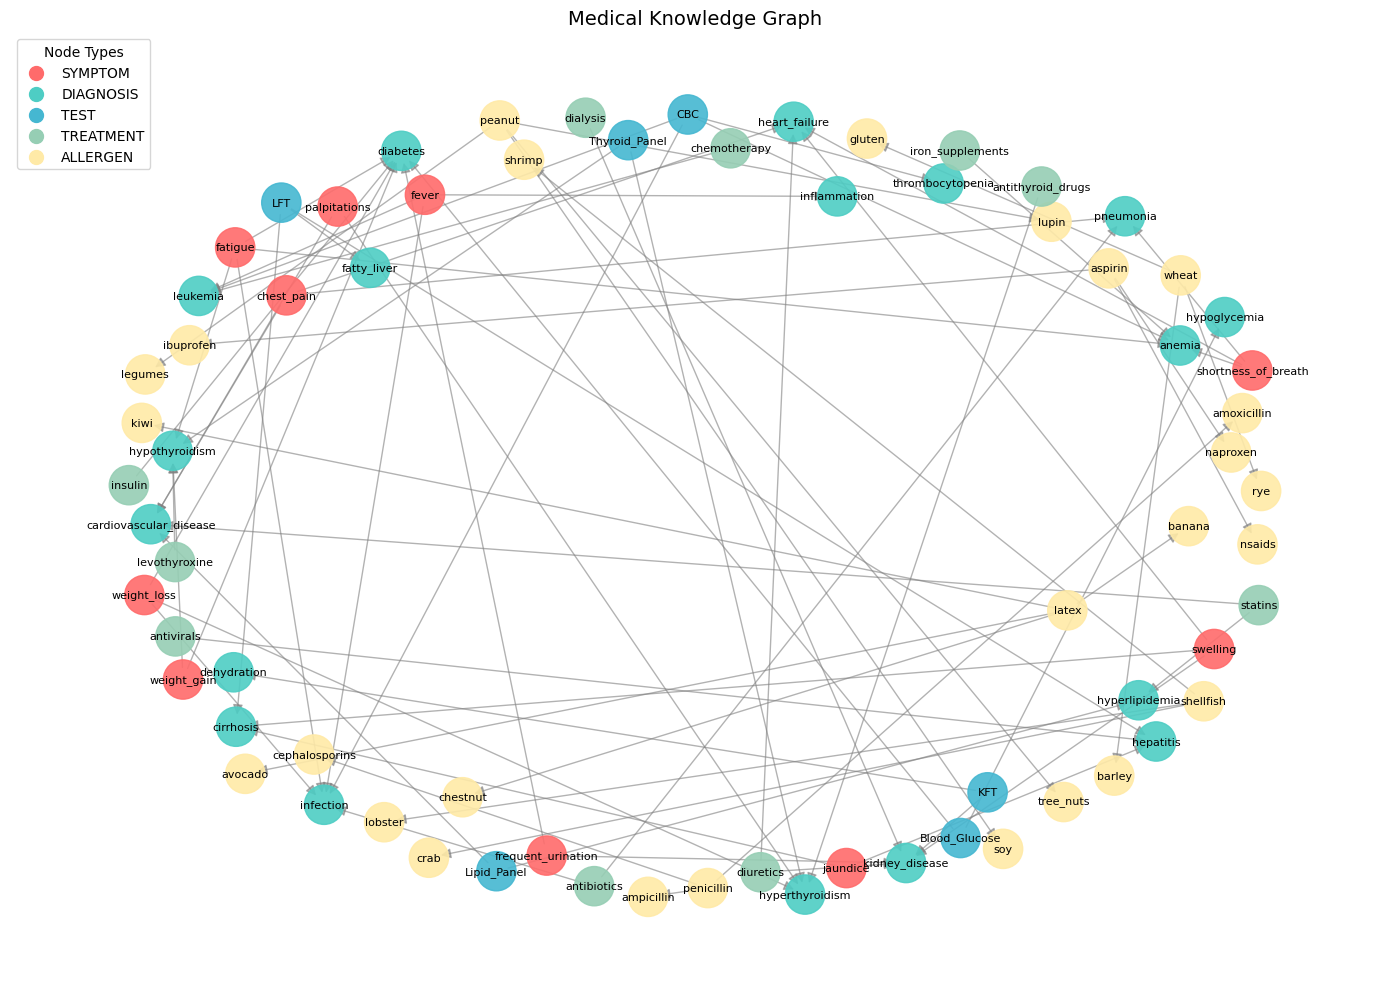

In [ ]:
# ============================================================================
# TODO 6.2: VISUALIZE THE KNOWLEDGE GRAPH
# ============================================================================

print("KNOWLEDGE GRAPH VISUALIZATION")
print("="*60)

# Color mapping for node types
color_map = {
    'SYMPTOM': '#ff6b6b',      # Red
    'DIAGNOSIS': '#4ecdc4',    # Teal
    'TEST': '#45b7d1',         # Blue
    'TREATMENT': '#96ceb4',    # Green
    'ALLERGEN': '#ffeaa7'      # Yellow
}

# Get node colors
node_colors = [color_map.get(medical_kg.graph.nodes[n].get('type', 'OTHER'), '#95a5a6')
               for n in medical_kg.graph.nodes()]

# Create visualization
plt.figure(figsize=(14, 10))
pos = nx.spring_layout(medical_kg.graph, k=2, iterations=50, seed=42)

nx.draw_networkx_nodes(medical_kg.graph, pos, node_color=node_colors,
                       node_size=800, alpha=0.9)
nx.draw_networkx_edges(medical_kg.graph, pos, edge_color='gray',
                       arrows=True, arrowsize=15, alpha=0.6)
nx.draw_networkx_labels(medical_kg.graph, pos, font_size=8)

# Legend
legend_elements = [plt.scatter([], [], c=color, s=100, label=node_type)
                   for node_type, color in color_map.items()]
plt.legend(handles=legend_elements, loc='upper left', title='Node Types')

plt.title('Medical Knowledge Graph', fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================================
# VALIDATION CELL 6.1: Test Knowledge Graph Reasoning
# ============================================================================

print("KNOWLEDGE GRAPH REASONING TESTS")
print("="*60)

# Test 1: Symptom to Diagnosis
print("\n[Test 1] Symptom-to-Diagnosis Reasoning")
symptoms = ['fatigue', 'shortness_of_breath']
result = medical_kg.find_diagnoses_for_symptoms(symptoms)
print(f"Symptoms: {symptoms}")
print(f"Possible diagnoses: {result['diagnoses'][:5]}")

# Test 2: Cross-Reactivity
print("\n[Test 2] Allergen Cross-Reactivity")
for allergen in ['peanut', 'penicillin', 'latex']:
    cross = medical_kg.get_cross_reactive(allergen)
    print(f"  {allergen} -> {cross}")

# Test 3: Treatment Lookup
print("\n[Test 3] Treatment Recommendations")
for diagnosis in ['anemia', 'infection', 'hypothyroidism']:
    treatments = medical_kg.get_treatments_for_diagnosis(diagnosis)
    print(f"  {diagnosis} -> {treatments}")

# Validation
print("\n" + "-"*40)
if medical_kg.graph.number_of_nodes() >= 20:
    print("VALIDATION PASSED: Graph has sufficient nodes")
else:
    print("NEEDS WORK: Add more nodes to the knowledge graph")

KNOWLEDGE GRAPH REASONING TESTS

[Test 1] Symptom-to-Diagnosis Reasoning
Symptoms: ['fatigue', 'shortness_of_breath']
Possible diagnoses: [('anemia', 2), ('hypothyroidism', 1), ('infection', 1), ('diabetes', 1), ('pneumonia', 1)]

[Test 2] Allergen Cross-Reactivity
  peanut -> ['tree_nuts', 'legumes', 'lupin', 'soy']
  penicillin -> ['amoxicillin', 'ampicillin', 'cephalosporins']
  latex -> ['banana', 'avocado', 'kiwi', 'chestnut']

[Test 3] Treatment Recommendations
  anemia -> ['iron_supplements']
  infection -> ['antibiotics']
  hypothyroidism -> ['levothyroxine']

----------------------------------------
VALIDATION PASSED: Graph has sufficient nodes


---
# WEEK 7: Evaluation & Testing Framework
---

## Learning Objectives
- Build systematic evaluation pipelines for AI agents
- Implement confidence thresholds and quality gates
- Track evaluation metrics in Langfuse

## Difficulty: Advanced

**HEALTHCARE CHALLENGE - Clinical AI Safety**:
- All agents must meet minimum confidence thresholds
- Critical findings must trigger appropriate urgency levels
- Cross-reactivity detection must be 100% reliable


In [ ]:
# ============================================================================
# TODO 7.1: IMPLEMENT EVALUATION FRAMEWORK
# ============================================================================

import time
from dataclasses import dataclass, field
from typing import List, Dict, Optional

@dataclass
class EvaluationResult:
    test_name: str
    passed: bool
    score: float
    expected: Dict
    actual: Dict
    latency_ms: float
    notes: str = ""

@dataclass
class EvaluationSuite:
    name: str
    results: List[EvaluationResult] = field(default_factory=list)

    def add(self, result: EvaluationResult):
        self.results.append(result)

    @property
    def pass_rate(self) -> float:
        if not self.results:
            return 0.0
        return sum(1 for r in self.results if r.passed) / len(self.results)

    @property
    def avg_score(self) -> float:
        if not self.results:
            return 0.0
        return sum(r.score for r in self.results) / len(self.results)

    @property
    def avg_latency(self) -> float:
        if not self.results:
            return 0.0
        return sum(r.latency_ms for r in self.results) / len(self.results)

    def report(self):
        print(f"\nEvaluation Suite: {self.name}")
        print("="*60)
        print(f"Tests run   : {len(self.results)}")
        print(f"Pass rate   : {self.pass_rate:.0%}")
        print(f"Avg score   : {self.avg_score:.3f}")
        print(f"Avg latency : {self.avg_latency:.0f} ms")
        print()
        for r in self.results:
            status = "PASS" if r.passed else "FAIL"
            print(f"  [{status}] {r.test_name} (score={r.score:.2f}, {r.latency_ms:.0f}ms)")
            if r.notes:
                print(f"         {r.notes}")


print("EvaluationResult, EvaluationSuite defined")


In [ ]:
# ============================================================================
# TODO 7.2: EVALUATE LAB INTERPRETER AGENT
# ============================================================================

print("LAB INTERPRETER AGENT - CBC Examples")
print("="*60)
print("Each invocation is traced to Langfuse\n")

cbc_examples = [
    {
        "report": """CBC Report - Patient A:
Hemoglobin: 10.2 g/dL (LOW)
WBC: 12,500 /uL (HIGH)
Platelet: 180,000 /uL (NORMAL)""",
        "expected_status": ["LOW", "HIGH", "NORMAL"],
        "expected_urgency": ["urgent", "stat"],
    },
    {
        "report": """CBC Report - Patient B:
Hemoglobin: 15.0 g/dL (NORMAL)
WBC: 5,500 /uL (NORMAL)
Platelet: 250,000 /uL (NORMAL)""",
        "expected_status": ["NORMAL"],
        "expected_urgency": ["routine"],
    },
    {
        "report": """CBC Report - Patient C:
Hemoglobin: 6.8 g/dL (CRITICAL_LOW)
WBC: 45,000 /uL (CRITICAL_HIGH)
Platelet: 28,000 /uL (CRITICAL_LOW)""",
        "expected_status": ["CRITICAL_LOW", "CRITICAL_HIGH"],
        "expected_urgency": ["stat", "emergency"],
    },
]

suite = EvaluationSuite("Lab Interpreter - CBC")

for i, example in enumerate(cbc_examples, 1):
    print(f"[CBC Test {i}]")
    t0 = time.time()
    result = lab_agent.interpret(example["report"], f"eval-patient-{i:03d}")
    latency = (time.time() - t0) * 1000

    if result.get("success"):
        r = result["result"]
        print(f"  Status    : {r['status']}")
        print(f"  Urgency   : {r['urgency']}")
        print(f"  Confidence: {r['confidence']:.2f}")
        print(f"  Significance: {r['clinical_significance'][:80]}...")

        status_ok = any(s in r["status"] for s in example["expected_status"])
        urgency_ok = r["urgency"] in example["expected_urgency"]
        confidence_ok = r["confidence"] >= 0.7
        passed = status_ok and confidence_ok
        score = (int(status_ok) + int(urgency_ok) + int(confidence_ok)) / 3.0

        suite.add(EvaluationResult(
            test_name=f"CBC-{i}",
            passed=passed,
            score=score,
            expected={"status": example["expected_status"], "urgency": example["expected_urgency"]},
            actual={"status": r["status"], "urgency": r["urgency"], "confidence": r["confidence"]},
            latency_ms=latency,
            notes=f"status_ok={status_ok} urgency_ok={urgency_ok} confidence_ok={confidence_ok}"
        ))
    else:
        print(f"  Error: {result.get('error', 'unknown')}")
        suite.add(EvaluationResult(
            test_name=f"CBC-{i}", passed=False, score=0.0,
            expected={}, actual={}, latency_ms=latency,
            notes=f"Agent error: {result.get('error', 'unknown')}"
        ))

suite.report()

# Log evaluation summary to Langfuse
if langfuse:
    langfuse.trace(
        name="eval-lab-cbc",
        session_id=SESSION_ID,
        metadata={"pass_rate": suite.pass_rate, "avg_score": suite.avg_score,
                  "avg_latency_ms": suite.avg_latency, "tests": len(suite.results)},
        tags=["evaluation", "lab", "cbc"]
    )


In [ ]:
# ============================================================================
# TODO 7.3: EVALUATE ALLERGY SAFETY AGENT
# ============================================================================

print("ALLERGY SAFETY AGENT - Cross-Reactivity Evaluation")
print("="*60)

allergy_cases = [
    {"doc": "Patient has documented peanut allergy with anaphylaxis history.", "allergen": "peanut",
     "must_include": ["tree_nuts", "legumes"]},
    {"doc": "Patient is allergic to penicillin — mild rash on prior exposure.", "allergen": "penicillin",
     "must_include": ["amoxicillin", "cephalosporins"]},
    {"doc": "Patient has latex allergy confirmed by skin-prick test.", "allergen": "latex",
     "must_include": ["banana", "avocado"]},
]

allergy_suite = EvaluationSuite("Allergy Safety - Cross-Reactivity")

for i, case in enumerate(allergy_cases, 1):
    print(f"[Allergy Test {i}] {case['allergen']}")
    t0 = time.time()
    result = allergy_agent.assess(case["doc"], f"allergy-eval-{i:03d}")
    latency = (time.time() - t0) * 1000

    if result.get("success"):
        r = result["result"]
        cross = [c.lower().replace(" ", "_") for c in r.get("cross_reactivities", [])]
        kg_cross = medical_kg.get_cross_reactive(case["allergen"])

        hits = [m for m in case["must_include"] if any(m in c for c in cross + [c.lower() for c in r.get("cross_reactivities",[])])]
        detection_rate = len(hits) / len(case["must_include"])
        passed = detection_rate >= 0.5 and r["confidence"] >= 0.7

        print(f"  Cross-reactivities: {r['cross_reactivities']}")
        print(f"  KG cross-reactivities: {kg_cross}")
        print(f"  Detection rate: {detection_rate:.0%}  Confidence: {r['confidence']:.2f}")

        allergy_suite.add(EvaluationResult(
            test_name=f"Allergy-{case['allergen']}",
            passed=passed,
            score=detection_rate * r["confidence"],
            expected={"cross_reactivities": case["must_include"]},
            actual={"cross_reactivities": cross, "confidence": r["confidence"]},
            latency_ms=latency,
            notes=f"detected {len(hits)}/{len(case['must_include'])} required cross-reactivities"
        ))
    else:
        print(f"  Error: {result.get('error', 'unknown')}")
        allergy_suite.add(EvaluationResult(
            test_name=f"Allergy-{case['allergen']}", passed=False, score=0.0,
            expected={}, actual={}, latency_ms=latency,
            notes=result.get("error", "unknown")
        ))

allergy_suite.report()

if langfuse:
    langfuse.trace(
        name="eval-allergy-cross-reactivity",
        session_id=SESSION_ID,
        metadata={"pass_rate": allergy_suite.pass_rate, "avg_score": allergy_suite.avg_score},
        tags=["evaluation", "allergy", "safety"]
    )


In [ ]:
# ============================================================================
# VALIDATION CELL 7.1: Overall Evaluation Report
# ============================================================================

print("WEEK 7 EVALUATION SUMMARY")
print("="*60)

for s in [suite, allergy_suite]:
    print(f"  {s.name:40s}  pass={s.pass_rate:.0%}  score={s.avg_score:.2f}")

overall_pass = suite.pass_rate >= 0.6 and allergy_suite.pass_rate >= 0.6
print()
if overall_pass:
    print("VALIDATION PASSED: Agents meet minimum quality thresholds")
else:
    print("NEEDS WORK: Some agents below quality threshold (60% pass rate required)")


---
# WEEK 8: Gradio Interactive Interface
---

## Learning Objectives
- Build a production-ready web interface for the clinical AI system
- Integrate all agents behind a unified Gradio frontend
- Support multi-role access from a single interface

## Difficulty: Intermediate

**HEALTHCARE CHALLENGE - Usability for Clinical Staff**:
- Clinicians need fast, intuitive access to AI assistance
- Interface must clearly display urgency and confidence levels
- Role selection enforces the RBAC controls built in Week 5


In [ ]:
# ============================================================================
# WEEK 8: INSTALL GRADIO
# ============================================================================

try:
    import gradio as gr
    print(f"Gradio already installed: {gr.__version__}")
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "gradio", "-q"], check=True)
    import gradio as gr
    print(f"Gradio installed: {gr.__version__}")

import os
IN_COLAB = 'google.colab' in str(get_ipython()) if hasattr(__builtins__, '__import__') else False
try:
    IN_COLAB = 'google.colab' in str(get_ipython())
except Exception:
    IN_COLAB = False

print(f"Running in Colab: {IN_COLAB}")


In [ ]:
# ============================================================================
# WEEK 8: DEFINE GRADIO INTERFACE FUNCTIONS
# ============================================================================

def clinical_query_interface(query: str, role_str: str) -> str:
    """Route a clinical query through the orchestrator and format the result."""
    if not query.strip():
        return "Please enter a clinical query."

    role_map = {
        "patient":     ClinicalRole.PATIENT,
        "clinician":   ClinicalRole.CLINICIAN,
        "radiologist": ClinicalRole.RADIOLOGIST,
        "coordinator": ClinicalRole.COORDINATOR,
    }
    role = role_map.get(role_str.lower(), ClinicalRole.COORDINATOR)

    result = orchestrator.process_with_tracing(query, role)

    if not result.get("allowed", True) and result.get("success") is False:
        return f"**Access Denied**\n\nRole `{role_str}` is not authorised to access `{result.get('domain', 'this')}` data."

    if not result.get("success"):
        return f"**Error:** {result.get('reason', result.get('agent_result', {}).get('error', 'Unknown error'))}"

    agent_result = result.get("agent_result", {}).get("result", {})
    domain = result.get("domain", "unknown")
    latency = result.get("latency_ms", 0)

    lines = [f"**Domain:** {domain.upper()}  |  **Role:** {role_str}  |  **Latency:** {latency:.0f} ms", ""]

    if domain == "lab":
        lines += [
            f"**Test:** {agent_result.get('test_name', 'N/A')}",
            f"**Status:** {agent_result.get('status', 'N/A')}",
            f"**Urgency:** {agent_result.get('urgency', 'N/A')}",
            f"**Confidence:** {agent_result.get('confidence', 0):.0%}",
            "",
            f"**Clinical Significance:** {agent_result.get('clinical_significance', 'N/A')}",
            "",
            "**Recommended Actions:**",
        ] + [f"- {a}" for a in agent_result.get("recommended_actions", [])]

    elif domain == "radiology":
        lines += [
            f"**Study:** {agent_result.get('study_type', 'N/A')} — {agent_result.get('body_region', 'N/A')}",
            f"**Urgency:** {agent_result.get('urgency', 'N/A')}",
            f"**Confidence:** {agent_result.get('confidence', 0):.0%}",
            f"**Impression:** {agent_result.get('impression', 'N/A')}",
            "",
            "**Findings:**",
        ] + [f"- {f}" for f in agent_result.get("findings", [])]

    elif domain == "allergy":
        lines += [
            f"**Allergen:** {agent_result.get('allergen', 'N/A')}",
            f"**Severity:** {agent_result.get('severity', 'N/A')}",
            f"**Confidence:** {agent_result.get('confidence', 0):.0%}",
            "",
            "**Cross-Reactivities:**",
        ] + [f"- {c}" for c in agent_result.get("cross_reactivities", [])] + [
            "",
            f"**Emergency Protocol:** {agent_result.get('emergency_protocol', 'N/A')}",
        ]

    return "\n".join(lines)


def allergy_check_interface(allergen: str) -> str:
    """Quick cross-reactivity check using the knowledge graph."""
    if not allergen.strip():
        return "Please enter an allergen name."

    key = allergen.strip().lower().replace(" ", "_")
    cross = medical_kg.get_cross_reactive(key)

    if cross:
        items = "\n".join(f"- {c.replace('_', ' ').title()}" for c in cross)
        return f"**Cross-Reactive Allergens for {allergen.title()}:**\n\n{items}\n\n> Always consult a clinician before prescribing or advising."
    else:
        agent_result = allergy_agent.assess(f"Patient has {allergen} allergy.", "gradio-check")
        if agent_result.get("success"):
            r = agent_result["result"]
            cross_list = r.get("cross_reactivities", [])
            if cross_list:
                items = "\n".join(f"- {c}" for c in cross_list)
                return f"**Cross-Reactive Allergens for {allergen.title()} (AI-assisted):**\n\n{items}"
        return f"No cross-reactivity data found for **{allergen}** in the knowledge graph. Please consult an allergist."


print("Gradio interface functions defined")


In [ ]:
# ============================================================================
# WEEK 8: LAUNCH GRADIO INTERFACE
# ============================================================================

with gr.Blocks(title="Healthcare Clinical Intelligence") as demo:
    gr.Markdown("# Healthcare Clinical Intelligence System")
    gr.Markdown("Multi-agent AI for clinical decision support with full observability")

    with gr.Tab("Clinical Query"):
        with gr.Row():
            query_input = gr.Textbox(label="Clinical Query", placeholder="Enter your question...", lines=3)
            role_input = gr.Dropdown(
                choices=["patient", "clinician", "radiologist", "coordinator"],
                value="coordinator",
                label="Role"
            )
        query_output = gr.Markdown(label="Response")
        query_btn = gr.Button("Submit Query")
        query_btn.click(clinical_query_interface, [query_input, role_input], query_output)

        gr.Examples(
            examples=[
                ["What do elevated hemoglobin levels indicate?", "clinician"],
                ["Cross-reactive allergens for peanut allergy?", "patient"],
                ["Chest X-ray findings for pneumonia", "radiologist"]
            ],
            inputs=[query_input, role_input]
        )

    with gr.Tab("Allergy Safety Check"):
        allergen_input = gr.Textbox(label="Allergen", placeholder="e.g., peanut, penicillin")
        allergen_output = gr.Markdown(label="Cross-Reactivity Alert")
        allergen_btn = gr.Button("Check Cross-Reactivity")
        allergen_btn.click(allergy_check_interface, allergen_input, allergen_output)

        gr.Examples(
            examples=[["peanut"], ["penicillin"], ["latex"], ["shellfish"]],
            inputs=[allergen_input]
        )

print("Gradio interface created")

if IN_COLAB:
    demo.launch(share=True)
else:
    print("Run demo.launch() to start the interface")


In [ ]:
# ============================================================================
# VALIDATION CELL 8.1: Test Interface Functions
# ============================================================================

print("WEEK 8 INTERFACE VALIDATION")
print("="*60)

# Test clinical query interface (no actual API call needed for routing test)
test_queries = [
    ("What do my CBC results mean?", "clinician"),
    ("Check peanut allergy", "patient"),
    ("Analyze chest X-ray", "radiologist"),
]

print("\n[Interface routing tests]")
for query, role in test_queries:
    routed = orchestrator.route_query(query)
    from_role = ClinicalRole(role)
    allowed = orchestrator.check_permission(from_role, routed)
    print(f"  '{query[:40]}...' | role={role} -> domain={routed}, allowed={allowed}")

# Test allergy knowledge graph check
print("\n[Knowledge graph allergy checks]")
for allergen in ["peanut", "penicillin", "latex"]:
    cross = medical_kg.get_cross_reactive(allergen)
    result_text = allergy_check_interface(allergen)
    status = "OK" if cross or "AI-assisted" in result_text or "No cross" in result_text else "FAIL"
    print(f"  [{status}] {allergen}: {len(cross)} cross-reactivities in KG")

print("\nGradio interface functions validated")
print("Launch demo.launch() or demo.launch(share=True) to start the web UI")
